# Singapore HDB Resale Prices: When Does a Town Premium Disappear?

This notebook investigates one question:

> **How much of the observed price difference between HDB towns reflects location, and how much reflects the mix of flats sold in each town?**

The analysis follows 222,066 resale registrations from January 2017 through December 2025. It first establishes data quality and representation, then follows Town coefficients through a sequence of hedonic regressions. The central non-obvious finding is a sign reversal for PASIR RIS relative to BEDOK. A final chronological prediction experiment tests whether the same preparation decisions improve performance on 2025 transactions.

The source records resale **registration dates** and excludes some transaction types, including sales between relatives and partial-share sales. Floor area can include purchased recess space, upgrading additions, or roof terraces. Results therefore describe the published transaction sample rather than all HDB homes.

Source: [HDB / data.gov.sg](https://data.gov.sg/datasets/d_8b84c4ee58e3cfc0ece0d773c8ca6abc/view).

**AI declaration:** OpenAI Codex assisted with code, analytical suggestions, and writing. The work was checked by executing the complete notebook, inspecting outputs, and verifying the chronological encodings and model comparisons. Group members remain responsible for understanding and independently verifying the submitted analysis.

## 1. Research design

The tempting interpretation of a Town price map is that high-price Towns command a location premium. That interpretation can be misleading because Towns sell different mixtures of floor areas, flat types, models, storeys, remaining leases, and calendar periods.

The explanatory analysis therefore estimates the same Town coefficients after adding controls in a fixed sequence:

| Model | Controls added |
|---|---|
| M0 | Town only |
| M1 | Registration month |
| M2 | Log floor area |
| M3 | Flat Type and Flat Model |
| M4 | Storey Range and remaining lease |

The main conclusion concerns how the Town coefficients change. M4 remains an observational hedonic regression: it estimates conditional differences, not the causal effect of moving the same flat between Towns.

The prediction analysis then compares minimally processed and systematically prepared data using the same basic method, OLS, and the same 2025 test records. Accuracy is evidence about preparation choices rather than the research goal.

## 2. Reproducible data snapshot

Run `uv sync --locked`, followed by `uv run jupyter lab`, from the project root. The notebook normally reuses the local snapshot. Set `REFRESH_DATA = True` only to replace it with a new official download, still filtered through December 2025. Metadata records the source, retrieval time, cutoff, and SHA-256 checksum.

In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import io
import json
import time

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 15)
pd.set_option("display.max_rows", 40)
pd.set_option("display.max_colwidth", 40)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

DATASET_ID = "d_8b84c4ee58e3cfc0ece0d773c8ca6abc"
SOURCE_URL = f"https://data.gov.sg/datasets/{DATASET_ID}/view"
CUTOFF = "2025-12"
REFRESH_DATA = False
SNAPSHOT = Path("data/raw/hdb_resale_2017_2025.csv")
METADATA = SNAPSHOT.with_suffix(".metadata.json")

In [2]:
if REFRESH_DATA or not SNAPSHOT.exists():
    api = f"https://api-open.data.gov.sg/v1/public/api/datasets/{DATASET_ID}"
    response = requests.get(f"{api}/initiate-download", timeout=60)
    response.raise_for_status()
    download = requests.get(f"{api}/poll-download", timeout=60).json()["data"]
    while not download.get("url"):
        time.sleep(15)
        download = requests.get(f"{api}/poll-download", timeout=60).json()["data"]

    response = requests.get(download["url"], timeout=120)
    response.raise_for_status()
    source = pd.read_csv(io.BytesIO(response.content), dtype="string")
    source_month = pd.to_datetime(source["month"], format="%Y-%m")
    snapshot = source.loc[source_month.between("2017-01-01", "2025-12-31")].copy()
    SNAPSHOT.parent.mkdir(parents=True, exist_ok=True)
    snapshot.to_csv(SNAPSHOT, index=False)
    metadata = {
        "dataset_id": DATASET_ID,
        "source_url": SOURCE_URL,
        "retrieved_at": datetime.now(ZoneInfo("Asia/Shanghai")).isoformat(),
        "cutoff_month": CUTOFF,
        "source_rows": len(source),
        "source_latest_month": source["month"].max(),
        "snapshot_rows": len(snapshot),
        "snapshot_first_month": snapshot["month"].min(),
        "snapshot_last_month": snapshot["month"].max(),
        "snapshot_sha256": hashlib.sha256(SNAPSHOT.read_bytes()).hexdigest(),
    }
    METADATA.write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")

metadata = json.loads(METADATA.read_text(encoding="utf-8"))
assert hashlib.sha256(SNAPSHOT.read_bytes()).hexdigest() == metadata["snapshot_sha256"]
display(pd.Series(metadata, name="Snapshot metadata").to_frame())

,Snapshot metadata
dataset_id,d_8b84c4ee58e3cfc0ece0d773c8ca6abc
source_url,https://data.gov.sg/datasets/d_8b84c...
retrieved_at,2026-10-11T21:23:29.895039+08:00
cutoff_month,2025-12
source_rows,242454
source_latest_month,2026-10
snapshot_rows,222066
snapshot_first_month,2017-01
snapshot_last_month,2025-12
snapshot_sha256,af2ed6574d542771426bf2236c122470d64f...


## 3. Raw profile and literal data quality

Use pandas' native inspection methods before conversion. `block` is read as a string because labels such as `273A` are identifiers. The literal audit checks missing values, blanks, outer whitespace, numeric parsing, label variants, and repeated public records.

The snapshot contains **308 groups of identical rows: 307 pairs and one triplet**. These produce 309 excess rows. Transaction IDs and unit numbers are unavailable, so identical public attributes may still represent separate sales. The main analysis retains them and later checks whether deduplication changes the conclusion.

In [3]:
raw = pd.read_csv(SNAPSHOT, dtype={"block": "string"})
display(raw.head())
raw.info()
display(raw.dtypes.rename("Inferred dtype").to_frame())
display(raw.describe())
display(raw.describe(include=["object", "string"]))

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
0,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.000,Improved,1979,61 years 04 months,232000.000
1,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.000,New Generation,1978,60 years 07 months,250000.000
2,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.000,New Generation,1980,62 years 05 months,262000.000
3,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.000,New Generation,1980,62 years 01 month,265000.000
4,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.000,New Generation,1980,62 years 05 months,265000.000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 222066 entries, 0 to 222065
Data columns (total 11 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   month                222066 non-null  object 
 1   town                 222066 non-null  object 
 2   flat_type            222066 non-null  object 
 3   block                222066 non-null  string 
 4   street_name          222066 non-null  object 
 5   storey_range         222066 non-null  object 
 6   floor_area_sqm       222066 non-null  float64
 7   flat_model           222066 non-null  object 
 8   lease_commence_date  222066 non-null  int64  
 9   remaining_lease      222066 non-null  object 
 10  resale_price         222066 non-null  float64
dtypes: float64(2), int64(1), object(7), string(1)
memory usage: 18.6+ MB


,Inferred dtype
month,object
town,object
flat_type,object
block,string[python]
street_name,object
storey_range,object
floor_area_sqm,float64
flat_model,object
lease_commence_date,int64
remaining_lease,object


,floor_area_sqm,lease_commence_date,resale_price
count,222066.000,222066.000,222066.000
mean,96.770,1996.435,524464.323
std,24.020,14.301,186593.819
min,31.000,1966.000,140000.000
25%,81.000,1985.000,385000.000
50%,93.000,1997.000,492000.000
75%,112.000,2012.000,630000.000
max,366.700,2021.000,1658888.000


,month,town,flat_type,block,street_name,storey_range,flat_model,remaining_lease
count,222066,222066,222066,222066,222066,222066,222066,222066
unique,108,26,7,2745,576,17,21,694
top,2024-07,SENGKANG,4 ROOM,2,YISHUN RING RD,04 TO 06,Model A,94 years 10 months
freq,3036,18155,94091,669,3178,50947,79348,1913


In [4]:
literal = pd.read_csv(SNAPSHOT, dtype="string")
quality = pd.DataFrame({
    "missing_count": literal.isna().sum(),
    "blank_count": literal.apply(lambda s: s.str.strip().eq("").sum()),
    "outer_whitespace_count": literal.apply(lambda s: s.ne(s.str.strip()).sum()),
    "unique_count": literal.nunique(),
})
display(quality)

duplicate_counts = raw.groupby(list(raw.columns), dropna=False).size().rename("occurrences")
duplicate_groups = duplicate_counts.loc[duplicate_counts.gt(1)].reset_index()
duplicate_groups.insert(0, "duplicate_group", np.arange(1, len(duplicate_groups) + 1))
with pd.option_context("display.max_columns", None):
    example_rows = raw.reset_index(names="source_row").merge(
        duplicate_groups.head(3), on=list(raw.columns)
    ).sort_values(["duplicate_group", "source_row"])
    display(example_rows[["duplicate_group", "occurrences", "source_row"] + list(raw.columns)])

,missing_count,blank_count,outer_whitespace_count,unique_count
month,0,0,0,108
town,0,0,0,26
flat_type,0,0,0,7
block,0,0,0,2745
street_name,0,0,0,576
storey_range,0,0,0,17
floor_area_sqm,0,0,0,343
flat_model,0,0,0,21
lease_commence_date,0,0,0,56
remaining_lease,0,0,0,694


,duplicate_group,occurrences,source_row,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
0,1,2,224,2017-01,BUKIT MERAH,4 ROOM,106,HENDERSON CRES,07 TO 09,81.000,Improved,1975,57 years,470000.000
1,1,2,243,2017-01,BUKIT MERAH,4 ROOM,106,HENDERSON CRES,07 TO 09,81.000,Improved,1975,57 years,470000.000
2,2,2,304,2017-01,CENTRAL AREA,3 ROOM,271,QUEEN ST,16 TO 18,68.000,Improved,1979,61 years 02 months,470000.000
3,2,2,305,2017-01,CENTRAL AREA,3 ROOM,271,QUEEN ST,16 TO 18,68.000,Improved,1979,61 years 02 months,470000.000
4,3,2,505,2017-01,JURONG EAST,4 ROOM,265,TOH GUAN RD,04 TO 06,101.000,Model A,1998,80 years 09 months,470000.000
5,3,2,510,2017-01,JURONG EAST,4 ROOM,265,TOH GUAN RD,04 TO 06,101.000,Model A,1998,80 years 09 months,470000.000


In [5]:
text_columns = ["town", "flat_type", "block", "street_name", "storey_range", "flat_model"]
variant_tables = []
for column in text_columns:
    labels = literal[column].dropna().drop_duplicates().to_frame("label")
    labels["normalized_label"] = labels["label"].str.strip().str.casefold()
    labels["column"] = column
    variant_tables.append(labels.loc[labels.duplicated("normalized_label", keep=False)])
display(pd.concat(variant_tables, ignore_index=True))

numeric_source_columns = ["floor_area_sqm", "resale_price", "lease_commence_date"]
display(pd.DataFrame({
    "parse_failure_count": {
        c: int((literal[c].notna() & pd.to_numeric(literal[c], errors="coerce").isna()).sum())
        for c in numeric_source_columns
    }
}))

,label,normalized_label,column


,parse_failure_count
floor_area_sqm,0
resale_price,0
lease_commence_date,0


## 4. Type conversion and cleaning decision

Convert Month to a date and elapsed-month index, Remaining Lease to fractional years, and Storey Range to ordered intervals. Storey Range identifies the interval in which the flat is located; it does not describe the number of floors occupied.

All records pass the basic missing, parsing, positivity, date, storey, and lease-domain rules. A separate consistency check compares recorded remaining lease with `99 - (registration year - lease start year)`. The 128 records differing by more than one year are excluded because their cause cannot be resolved from the dataset. They represent only 0.058% of the snapshot, and a later sensitivity test restores them. `lease_commence_date` is then omitted from models because registration time and remaining lease already carry approximately the same information.

In [6]:
df = raw.copy()
for column in literal.columns.difference(numeric_source_columns):
    df[column] = literal[column].str.strip().replace("", pd.NA)
for column in ["town", "flat_type", "street_name"]:
    df[column] = df[column].str.upper()
for column in numeric_source_columns:
    df[column] = pd.to_numeric(literal[column], errors="coerce")

df["transaction_date"] = pd.to_datetime(df["month"], format="%Y-%m", errors="coerce")
df["transaction_year"] = df["transaction_date"].dt.year
df["month_index"] = (df["transaction_year"] - 2017) * 12 + df["transaction_date"].dt.month - 1

storeys = df["storey_range"].str.extract(r"^(\d{2}) TO (\d{2})$").astype(float)
df["storey_lower"] = storeys[0]
df["storey_upper"] = storeys[1]
storey_order = (
    df[["storey_range", "storey_lower"]].dropna().drop_duplicates()
    .sort_values("storey_lower")["storey_range"].tolist()
)
storey_mapping = {label: rank for rank, label in enumerate(storey_order)}
df["storey_ordinal"] = df["storey_range"].map(storey_mapping)

lease_parts = df["remaining_lease"].str.extract(r"^(\d+) years?(?: (\d+) months?)?$").astype(float)
df["remaining_lease_years"] = lease_parts[0] + lease_parts[1].fillna(0) / 12

In [7]:
issues = pd.DataFrame(index=df.index)
issues["missing_required_field"] = df[raw.columns].isna().any(axis=1)
issues["invalid_month"] = df["transaction_date"].isna() | ~df["month"].str.fullmatch(r"\d{4}-\d{2}", na=False)
issues["outside_snapshot_period"] = ~df["transaction_date"].between("2017-01-01", "2025-12-31")
for column in numeric_source_columns:
    issues[f"invalid_{column}"] = ~np.isfinite(df[column]) | df[column].le(0)
issues["invalid_lease_start_year"] = (
    df["lease_commence_date"].mod(1).ne(0)
    | df["lease_commence_date"].gt(df["transaction_year"])
)
issues["invalid_storey_range"] = (
    df["storey_lower"].isna() | df["storey_lower"].le(0)
    | df["storey_upper"].lt(df["storey_lower"])
)
issues["invalid_remaining_lease"] = (
    df["remaining_lease_years"].isna()
    | ~df["remaining_lease_years"].between(0, 99)
    | lease_parts[1].fillna(0).ge(12)
)
display(issues.sum().rename("Flagged rows").to_frame())

invalid_rows = issues.any(axis=1)
invalid_records = pd.concat([df.loc[invalid_rows], issues.loc[invalid_rows]], axis=1)
display(invalid_records.head(10))
df = df.loc[~invalid_rows].copy()
display(pd.Series({
    "snapshot_rows": len(raw),
    "removed_invalid_rows": int(invalid_rows.sum()),
    "analysis_rows": len(df),
    "duplicates_retained": int(df.duplicated(subset=list(raw.columns)).sum()),
}, name="Cleaning decisions").to_frame())

,Flagged rows
missing_required_field,0
invalid_month,0
outside_snapshot_period,0
invalid_floor_area_sqm,0
invalid_resale_price,0
invalid_lease_commence_date,0
invalid_lease_start_year,0
invalid_storey_range,0
invalid_remaining_lease,0


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,...,outside_snapshot_period,invalid_floor_area_sqm,invalid_resale_price,invalid_lease_commence_date,invalid_lease_start_year,invalid_storey_range,invalid_remaining_lease


,Cleaning decisions
snapshot_rows,222066
removed_invalid_rows,0
analysis_rows,222066
duplicates_retained,309


In [8]:
expected_lease = 99 - (df["transaction_year"] - df["lease_commence_date"])
lease_residual = df["remaining_lease_years"] - expected_lease
lease_exclusion = lease_residual.abs().gt(1 + 1e-8)
lease_excluded = df.loc[lease_exclusion].copy()
lease_excluded["lease_residual_years"] = lease_residual.loc[lease_exclusion]
display(pd.Series({
    "lease_inconsistent_rows_excluded": int(lease_exclusion.sum()),
    "excluded_pct": 100 * lease_exclusion.mean(),
    "retained_analysis_rows": int((~lease_exclusion).sum()),
}, name="Lease consistency decision").to_frame())
df = df.loc[~lease_exclusion].copy()

,Lease consistency decision
lease_inconsistent_rows_excluded,128.000
excluded_pct,0.058
retained_analysis_rows,221938.000


## 5. Feature preparation

Flat Type and Flat Model are categorical. Their full one-hot encodings are retained in data tables, while pie charts combine individually sub-1% slices only for readability. Storey Range receives an ordinal code for ordered summaries, but the explanatory regression uses categorical intervals so that it does not impose equal price increments between ranges.

Address must be treated hierarchically. `block` alone is not a location; the building-level public address is Town + Street Name + Block.

Category distribution: flat_type


,count,share_pct,rare_below_1pct
flat_type,,,
4 ROOM,94030,42.368,False
5 ROOM,54483,24.549,False
3 ROOM,52836,23.807,False
EXECUTIVE,15933,7.179,False
2 ROOM,4492,2.024,False
MULTI-GENERATION,84,0.038,True
1 ROOM,80,0.036,True


Category distribution: flat_model


,count,share_pct,rare_below_1pct
flat_model,,,
Model A,79282,35.723,False
Improved,54249,24.443,False
New Generation,27178,12.246,False
Premium Apartment,24496,11.037,False
Simplified,8508,3.834,False
Apartment,7980,3.596,False
Maisonette,6113,2.754,False
Standard,5957,2.684,False
DBSS,3556,1.602,False


,flat_type_1 ROOM,flat_type_2 ROOM,flat_type_3 ROOM,flat_type_4 ROOM,flat_type_5 ROOM,flat_type_EXECUTIVE,flat_type_MULTI-GENERATION,...,flat_model_Premium Apartment Loft,flat_model_Premium Maisonette,flat_model_Simplified,flat_model_Standard,flat_model_Terrace,flat_model_Type S1,flat_model_Type S2
0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0
1,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0
2,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0
3,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0
4,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0


,One-hot share (%)
flat_type_1 ROOM,0.036
flat_type_2 ROOM,2.024
flat_type_3 ROOM,23.807
flat_type_4 ROOM,42.368
flat_type_5 ROOM,24.549
flat_type_EXECUTIVE,7.179
flat_type_MULTI-GENERATION,0.038
flat_model_2-room,0.163
flat_model_3Gen,0.030
flat_model_Adjoined flat,0.170


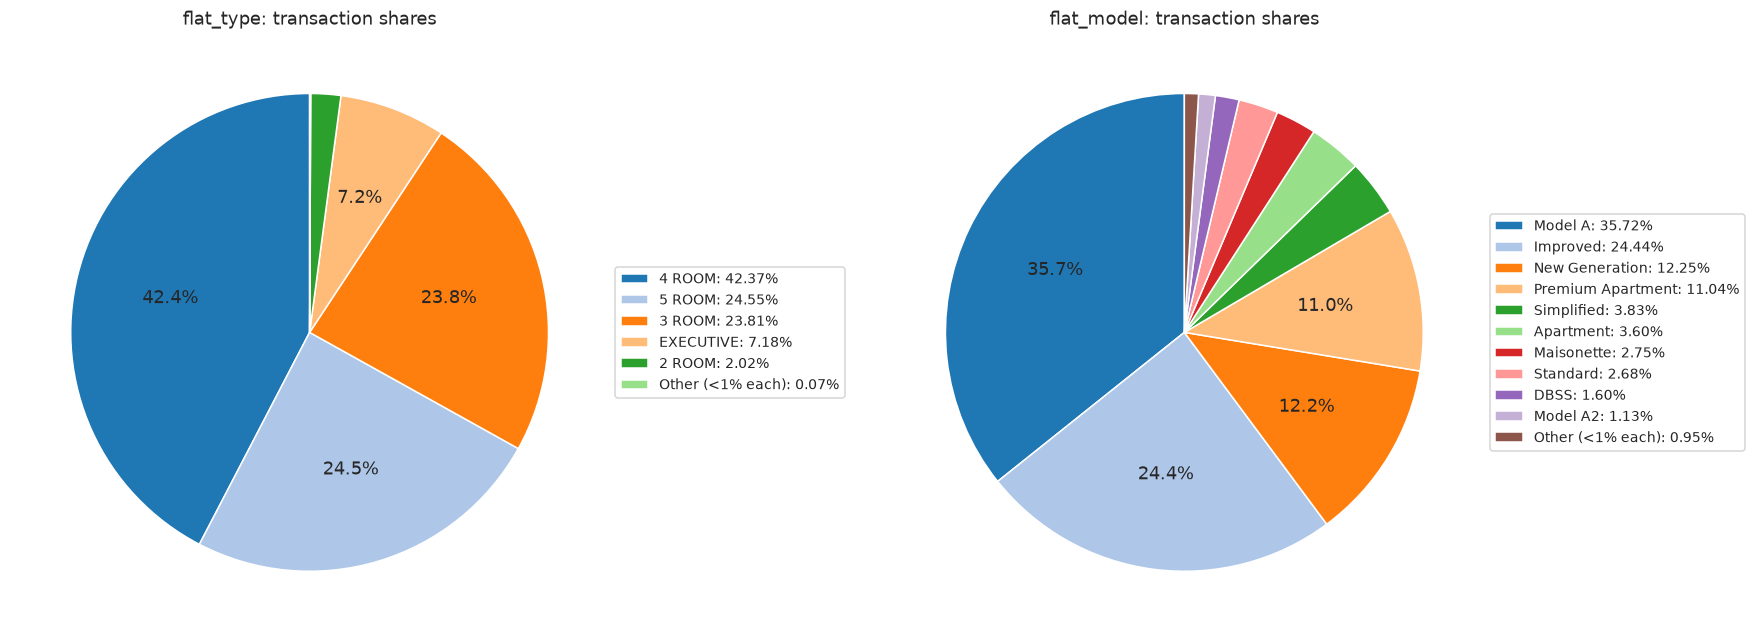

In [9]:
def category_pie(shares, ax, title):
    """Combine small slices for display while preserving the original statistics."""
    visible = shares.loc[shares.ge(1)].copy()
    small = shares.loc[shares.lt(1)].sum()
    if small > 0:
        visible.loc["Other (<1% each)"] = small
    wedges, _, _ = ax.pie(
        visible, startangle=90,
        autopct=lambda pct: f"{pct:.1f}%" if pct >= 5 else "",
        colors=sns.color_palette("tab20", len(visible)),
        wedgeprops={"edgecolor": "white"},
    )
    labels = [f"{label}: {share:.2f}%" for label, share in visible.items()]
    ax.legend(wedges, labels, loc="center left", bbox_to_anchor=(1, .5), fontsize=9)
    ax.set_title(title)


category_columns = ["flat_type", "flat_model"]
category_tables = {}
for column in category_columns:
    counts = df[column].value_counts()
    table = counts.rename("count").to_frame()
    table["share_pct"] = counts / len(df) * 100
    table["rare_below_1pct"] = table["share_pct"].lt(1)
    category_tables[column] = table
    print(f"Category distribution: {column}")
    display(table)

one_hot = pd.get_dummies(df[category_columns], prefix=category_columns, dtype=int)
display(one_hot.head())
display(one_hot.mean().mul(100).rename("One-hot share (%)").to_frame())
for column in category_columns:
    assert one_hot.filter(like=f"{column}_").sum(axis=1).eq(1).all()

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for column, ax in zip(category_columns, axes):
    category_pie(category_tables[column]["share_pct"], ax, f"{column}: transaction shares")
plt.tight_layout()
plt.show()

,ordinal,lower,upper,count,share_pct
storey_range,,,,,
01 TO 03,0,1.000,3.000,39118,17.626
04 TO 06,1,4.000,6.000,50919,22.943
07 TO 09,2,7.000,9.000,46557,20.977
10 TO 12,3,10.000,12.000,41453,18.678
13 TO 15,4,13.000,15.000,21370,9.629
16 TO 18,5,16.000,18.000,10002,4.507
19 TO 21,6,19.000,21.000,4302,1.938
22 TO 24,7,22.000,24.000,3017,1.359
25 TO 27,8,25.000,27.000,1876,0.845


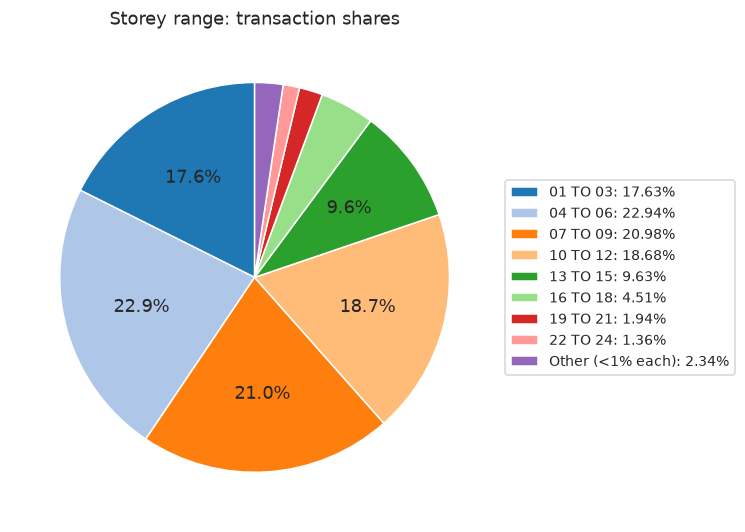

In [10]:
storey_table = df.groupby("storey_range").agg(
    ordinal=("storey_ordinal", "first"),
    lower=("storey_lower", "first"),
    upper=("storey_upper", "first"),
    count=("resale_price", "size"),
).reindex(storey_order)
storey_table["share_pct"] = storey_table["count"] / len(df) * 100
display(storey_table)
fig, ax = plt.subplots(figsize=(9, 5))
category_pie(storey_table["share_pct"], ax, "Storey range: transaction shares")
plt.tight_layout()
plt.show()

In [11]:
address_levels = [
    ["town"], ["street_name"], ["block"],
    ["town", "street_name"], ["town", "block"], ["street_name", "block"],
    ["town", "street_name", "block"],
]
address_summary = []
for columns in address_levels:
    sizes = df.groupby(columns).size()
    address_summary.append({
        "level": " + ".join(columns),
        "unique_combinations": len(sizes),
        "min_transactions": sizes.min(),
        "median_transactions": sizes.median(),
        "max_transactions": sizes.max(),
    })
address_summary = pd.DataFrame(address_summary)
display(address_summary)

address_counts = df.groupby(["town", "street_name", "block"]).size().rename("transactions")
display(address_counts.sort_values(ascending=False).head(10).to_frame())
display(pd.Series({
    "street_names_in_multiple_towns": int(df.groupby("street_name")["town"].nunique().gt(1).sum()),
    "block_labels_on_multiple_streets": int(df.groupby("block")["street_name"].nunique().gt(1).sum()),
}, name="Address ambiguity").to_frame())

,level,unique_combinations,min_transactions,median_transactions,max_transactions
0,town,26,542,7577.000,18140
1,street_name,576,1,277.500,3177
2,block,2745,1,51.000,669
3,town + street_name,576,1,277.500,3177
4,town + block,9097,1,21.000,177
5,street_name + block,9670,1,20.000,172
6,town + street_name + block,9670,1,20.000,172


transactions
town        street_name      block              
PUNGGOL     PUNGGOL WALK     308A            172
                             308C            154
QUEENSTOWN  DAWSON RD        87              140
PUNGGOL     PUNGGOL WALK     310B            139
TOA PAYOH   LOR 1A TOA PAYOH 139A            139
QUEENSTOWN  DAWSON RD        88              135
CLEMENTI    CLEMENTI AVE 4   311B            124
QUEENSTOWN  DAWSON RD        86              123
JURONG WEST BOON LAY AVE     187             123
PUNGGOL     PUNGGOL WALK     308B            116

,Address ambiguity
street_names_in_multiple_towns,0
block_labels_on_multiple_streets,1499


### 5.1 Geographic proxy and historical address encoding

The official URA Master Plan 2019 planning-area polygons provide an aggregate map. They are proxies rather than verified HDB-town or building boundaries. `KALLANG/WHAMPOA` is associated with Kallang, and the eleven Central Area planning polygons are dissolved to `CENTRAL AREA`.

For prediction, the address hierarchy is encoded as global → Town → Town + Street → Town + Street + Block. Each level shrinks towards its parent. Every year's encoding uses only earlier years, so a transaction's own price and future prices never enter its feature. The address encoding is used for prediction only; it is not interpreted as a causal location coefficient.

In [12]:
BOUNDARY_ID = "d_4765db0e87b9c86336792efe8a1f7a66"
BOUNDARY_URL = f"https://data.gov.sg/datasets/{BOUNDARY_ID}/view"
BOUNDARY_PATH = Path("data/raw/ura_mp2019_planning_areas.geojson")
if not BOUNDARY_PATH.exists():
    url = f"https://api-open.data.gov.sg/v1/public/api/datasets/{BOUNDARY_ID}/poll-download"
    download_url = requests.get(url, timeout=60).json()["data"]["url"]
    response = requests.get(download_url, timeout=120)
    response.raise_for_status()
    BOUNDARY_PATH.write_bytes(response.content)
    boundary_metadata = {
        "dataset_id": BOUNDARY_ID, "source_url": BOUNDARY_URL,
        "retrieved_at": datetime.now(ZoneInfo("Asia/Shanghai")).isoformat(),
        "sha256": hashlib.sha256(response.content).hexdigest(),
    }
    BOUNDARY_PATH.with_suffix(".metadata.json").write_text(
        json.dumps(boundary_metadata, indent=2) + "\n", encoding="utf-8"
    )

areas = gpd.read_file(BOUNDARY_PATH).to_crs(epsg=3414)
areas["map_town"] = areas["PLN_AREA_N"].replace({"KALLANG": "KALLANG/WHAMPOA"})
areas.loc[areas["CA_IND"].eq("Y"), "map_town"] = "CENTRAL AREA"
town_boundaries = areas[["map_town", "geometry"]].dissolve(by="map_town").reset_index()
town_statistics = df.groupby("town").agg(
    transactions=("resale_price", "size"), median_price=("resale_price", "median")
)
town_statistics["share_pct"] = town_statistics["transactions"] / len(df) * 100
town_map = town_boundaries.merge(town_statistics, left_on="map_town", right_index=True, how="left")
display(pd.Series({
    "HDB_town_labels": df["town"].nunique(),
    "matched_town_labels": df["town"].isin(town_boundaries["map_town"]).groupby(df["town"]).all().sum(),
    "Central_Area_planning_polygons": areas["CA_IND"].eq("Y").sum(),
}, name="Map matching audit").to_frame())
display(town_statistics.sort_values("transactions", ascending=False).head())

,Map matching audit
HDB_town_labels,26
matched_town_labels,26
Central_Area_planning_polygons,11


,transactions,median_price,share_pct
town,,,
SENGKANG,18140,515000.000,8.173
PUNGGOL,16146,525944.000,7.275
WOODLANDS,15743,455000.000,7.093
TAMPINES,15144,538888.000,6.824
YISHUN,15129,428000.000,6.817


In [13]:
address_columns = ["town", "street_name", "block"]


def hierarchical_target_encode(reference, addresses):
    """Fit hierarchical means on reference prices and transform address-only rows."""
    global_mean = reference["resale_price"].mean()
    result = pd.DataFrame(index=addresses.index)
    parent = None
    for level, (strength, name) in enumerate(zip([50, 20, 10], ["town_te", "street_te", "address_te"]), 1):
        keys = address_columns[:level]
        stats = reference.groupby(keys)["resale_price"].agg(["sum", "count"]).reset_index()
        if level == 1:
            stats["prior"] = global_mean
            fallback = global_mean
        else:
            stats = stats.merge(parent.rename(columns={"encoding": "prior"}), on=keys[:-1])
            fallback = result.iloc[:, -1]
        stats["encoding"] = (stats["sum"] + strength * stats["prior"]) / (stats["count"] + strength)
        parent = stats[keys + ["encoding"]]
        mapped = addresses[keys].merge(parent, on=keys, how="left", sort=False)["encoding"]
        result[name] = pd.Series(mapped.to_numpy(), index=addresses.index).fillna(fallback)
    return result


encoding_folds = []
for year in sorted(df["transaction_year"].unique()):
    if year == 2017:
        continue
    reference = df.loc[df["transaction_year"].lt(year)]
    current = df.loc[df["transaction_year"].eq(year)]
    fold = hierarchical_target_encode(reference, current[address_columns])
    fold["encoding_year"] = int(year)
    fold["reference_last_year"] = int(reference["transaction_year"].max())
    fold["split"] = "test" if year == 2025 else "train"
    encoding_folds.append(fold)

address_encoding = pd.concat(encoding_folds).sort_index()
df["address_te"] = address_encoding["address_te"]
assert address_encoding["reference_last_year"].lt(address_encoding["encoding_year"]).all()
assert address_encoding[["town_te", "street_te", "address_te"]].notna().all().all()
display(address_encoding.groupby(["encoding_year", "reference_last_year", "split"]).size().rename("rows").to_frame())
display(df.loc[address_encoding.index, ["month"] + address_columns].join(
    address_encoding[["town_te", "street_te", "address_te"]]
).head(8))

,,,rows
encoding_year,reference_last_year,split,
2018,2017,train,21557
2019,2018,train,22185
2020,2019,train,23333
2021,2020,train,29081
2022,2021,train,26715
2023,2022,train,25724
2024,2023,train,27812
2025,2024,test,25022


,month,town,street_name,block,town_te,street_te,address_te
20509,2018-01,ANG MO KIO,ANG MO KIO AVE 3,314,423571.876,382984.290,322873.112
20510,2018-01,ANG MO KIO,ANG MO KIO AVE 4,109,423571.876,380927.815,357251.656
20511,2018-01,ANG MO KIO,ANG MO KIO AVE 5,150,423571.876,385548.295,405421.765
20512,2018-01,ANG MO KIO,ANG MO KIO AVE 10,559,423571.876,360718.873,344145.915
20513,2018-01,ANG MO KIO,ANG MO KIO AVE 10,461,423571.876,360718.873,349156.338
20514,2018-01,ANG MO KIO,ANG MO KIO AVE 10,466,423571.876,360718.873,339227.766
20515,2018-01,ANG MO KIO,ANG MO KIO AVE 5,152,423571.876,385548.295,385548.295
20516,2018-01,ANG MO KIO,ANG MO KIO AVE 3,348,423571.876,382984.290,389820.241


## 6. Numeric distributions and valid tails

Summarize area, price, remaining lease, storey, time, and lease start year. Histograms combine a KDE with quartile lines. Storey uses a wider smoothing bandwidth because its code is discrete.

IQR flags describe distribution tails rather than confirmed errors. Area is also checked within Flat Type because a globally unusual area can be ordinary for a larger flat. Price and area tails remain in the main sample unless a model comparison provides evidence for removal.

In [14]:
numeric_columns = [
    "floor_area_sqm", "resale_price", "remaining_lease_years",
    "storey_ordinal", "month_index", "lease_commence_date",
]
numeric_summary = df[numeric_columns].describe(percentiles=[.01, .25, .5, .75, .99]).T
numeric_summary["skewness"] = df[numeric_columns].skew()
display(numeric_summary)

q1 = df[numeric_columns].quantile(.25)
q3 = df[numeric_columns].quantile(.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
outlier_flags = df[numeric_columns].lt(lower_fence) | df[numeric_columns].gt(upper_fence)
outlier_summary = pd.DataFrame({
    "lower_fence": lower_fence, "upper_fence": upper_fence,
    "lower_tail_count": df[numeric_columns].lt(lower_fence).sum(),
    "upper_tail_count": df[numeric_columns].gt(upper_fence).sum(),
    "outlier_count": outlier_flags.sum(),
    "outlier_pct": outlier_flags.mean() * 100,
})
display(outlier_summary)

,count,mean,std,min,1%,25%,50%,75%,99%,max,skewness
floor_area_sqm,221938.000,96.773,24.022,31.000,47.000,81.000,93.000,112.000,151.000,366.700,0.257
resale_price,221938.000,524419.745,186582.362,140000.000,230000.000,385000.000,492000.000,630000.000,1070000.000,1658888.000,0.960
remaining_lease_years,221938.000,74.249,14.232,40.083,46.250,62.500,74.083,88.667,95.250,97.750,-0.020
storey_ordinal,221938.000,2.256,1.980,0.000,0.000,1.000,2.000,3.000,9.000,16.000,1.606
month_index,221938.000,56.178,30.181,0.000,1.000,31.000,57.000,82.000,106.000,107.000,-0.120
lease_commence_date,221938.000,1996.431,14.301,1966.000,1969.000,1985.000,1997.000,2012.000,2020.000,2021.000,0.064


,lower_fence,upper_fence,lower_tail_count,upper_tail_count,outlier_count,outlier_pct
floor_area_sqm,34.500,158.500,102,1085,1187,0.535
resale_price,17500.000,997500.000,0,4054,4054,1.827
remaining_lease_years,23.250,127.917,0,0,0,0.000
storey_ordinal,-2.000,6.000,0,8217,8217,3.702
month_index,-45.500,158.500,0,0,0,0.000
lease_commence_date,1944.500,2052.500,0,0,0,0.000


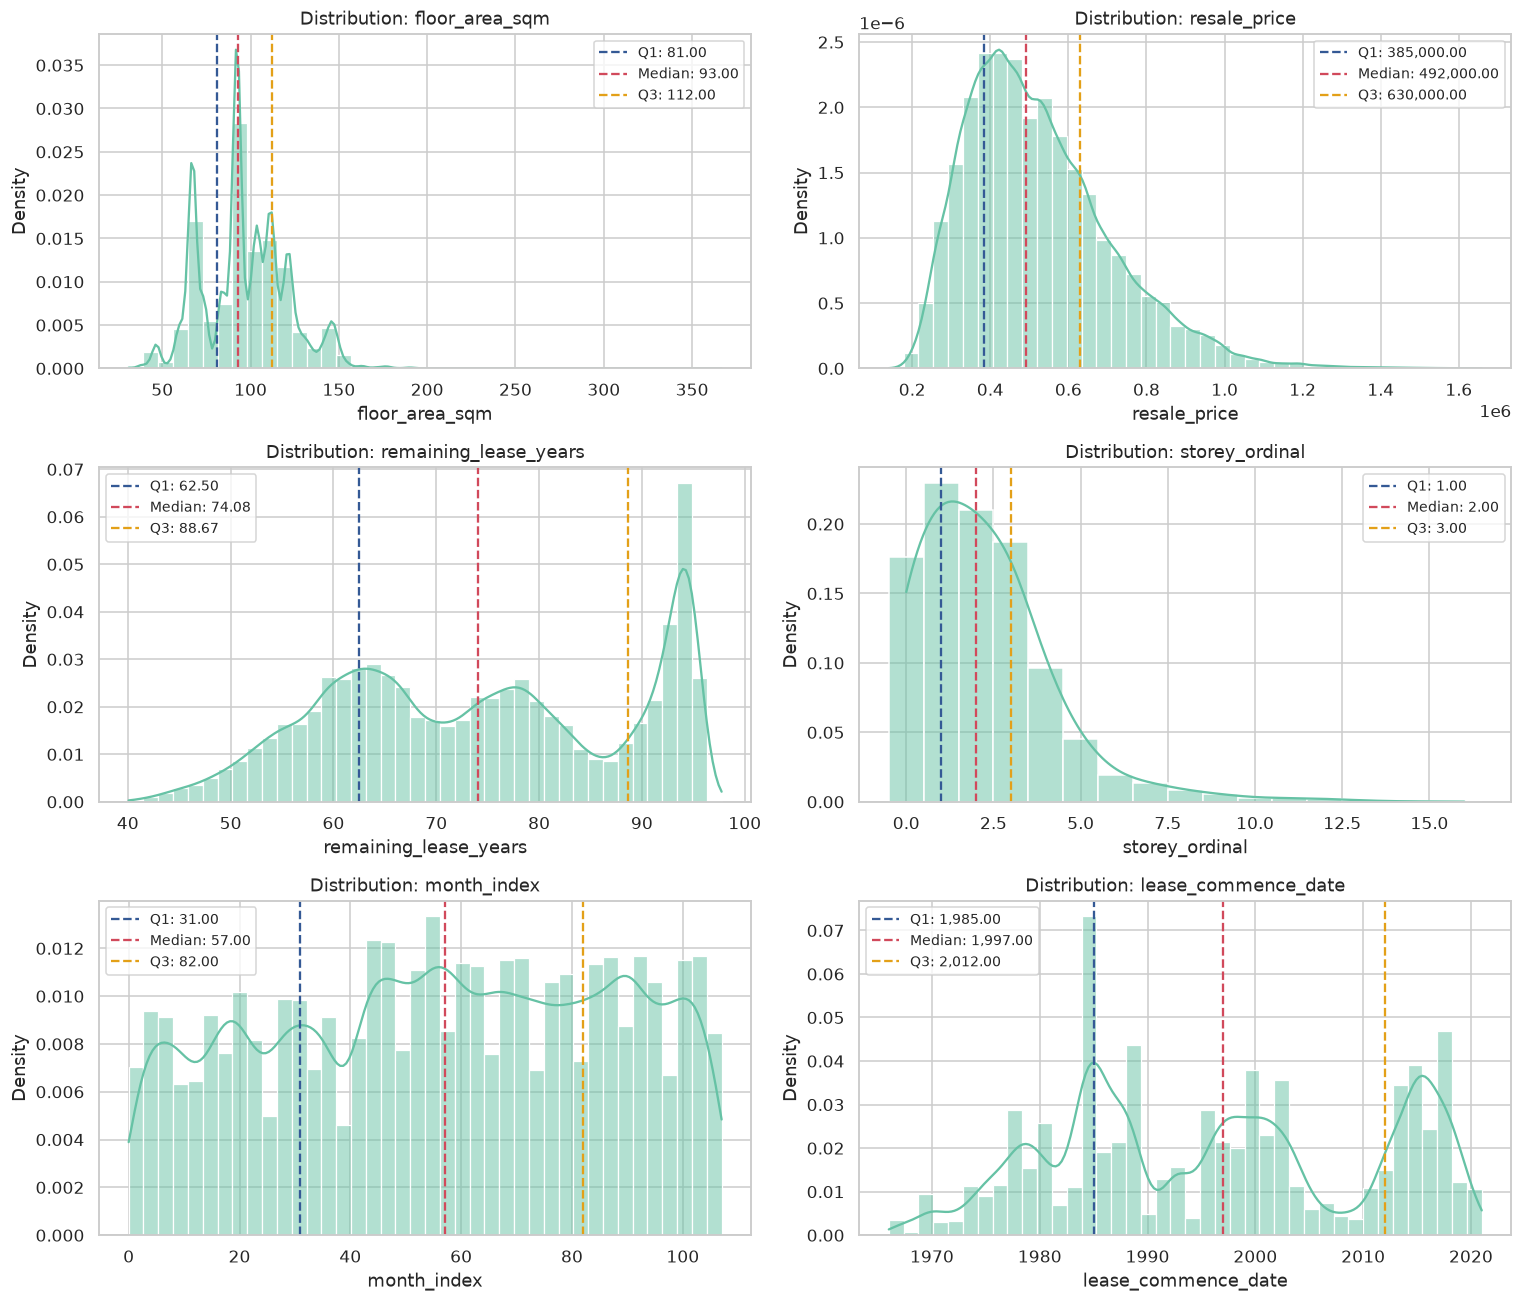

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
182823,2024-07,KALLANG/WHAMPOA,3 ROOM,53,JLN MA'MOR,01 TO 03,366.700,Terrace,1972,47 years,1568000.000
19693,2017-12,KALLANG/WHAMPOA,3 ROOM,65,JLN MA'MOR,01 TO 03,249.000,Terrace,1972,53 years 07 months,1053888.000
92512,2021-03,BISHAN,EXECUTIVE,446,BRIGHT HILL DR,07 TO 09,243.000,Maisonette,1990,68 years 01 month,1092888.000
94959,2021-04,BISHAN,EXECUTIVE,454,SIN MING AVE,10 TO 12,243.000,Maisonette,1989,67 years 08 months,1001000.000
107851,2021-09,KALLANG/WHAMPOA,3 ROOM,46,JLN BAHAGIA,01 TO 03,241.000,Terrace,1972,49 years 10 months,1235000.000
35797,2018-09,KALLANG/WHAMPOA,3 ROOM,41,JLN BAHAGIA,01 TO 03,237.000,Terrace,1972,52 years 10 months,1185000.000
95808,2021-04,KALLANG/WHAMPOA,3 ROOM,61,JLN TENTERAM,01 TO 03,222.000,Terrace,1972,50 years 03 months,1100000.000
8868,2017-06,KALLANG/WHAMPOA,3 ROOM,38,JLN BAHAGIA,01 TO 03,215.000,Terrace,1972,54 years 01 month,830000.000


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
212073,2025-06,QUEENSTOWN,5 ROOM,92,DAWSON RD,22 TO 24,122.000,Premium Apartment Loft,2016,89 years 11 months,1658888.000
199476,2025-11,BISHAN,5 ROOM,275A,BISHAN ST 24,34 TO 36,120.000,DBSS,2011,84 years 10 months,1632000.000
199498,2025-11,BISHAN,EXECUTIVE,135,BISHAN ST 12,22 TO 24,163.000,Maisonette,1987,60 years 08 months,1600000.000
202785,2025-08,CENTRAL AREA,5 ROOM,1G,CANTONMENT RD,49 TO 51,105.000,Type S2,2011,84 years 05 months,1600000.000
218475,2025-01,TOA PAYOH,5 ROOM,138A,LOR 1A TOA PAYOH,19 TO 21,117.000,DBSS,2012,86 years 06 months,1600000.000
202786,2025-09,CENTRAL AREA,5 ROOM,1A,CANTONMENT RD,40 TO 42,107.000,Type S2,2011,84 years 04 months,1590000.000
174171,2024-06,BUKIT MERAH,5 ROOM,9B,BOON TIONG RD,34 TO 36,112.000,Improved,2016,90 years 08 months,1588000.000
174172,2024-06,BUKIT MERAH,5 ROOM,96A,HENDERSON RD,46 TO 48,113.000,Improved,2019,94 years,1588000.000


In [15]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for column, ax in zip(numeric_columns, axes.flat):
    is_storey = column == "storey_ordinal"
    sns.histplot(data=df, x=column, bins=40, discrete=is_storey, stat="density", kde=True,
                 kde_kws={"cut": 0, "bw_adjust": 4 if is_storey else 1}, ax=ax)
    for quantile, label, color in [(0.25, "Q1", "#345995"), (0.5, "Median", "#d1495b"), (0.75, "Q3", "#e3a018")]:
        value = df[column].quantile(quantile)
        ax.axvline(value, linestyle="--", color=color, label=f"{label}: {value:,.2f}")
    ax.set_title(f"Distribution: {column}")
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

display(df.nlargest(8, "floor_area_sqm")[list(raw.columns)])
display(df.nlargest(8, "resale_price")[list(raw.columns)])

In [16]:
type_outliers = df.groupby("flat_type")["floor_area_sqm"].agg(
    q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75), count="size"
)
type_outliers["lower_fence"] = type_outliers["q1"] - 1.5 * (type_outliers["q3"] - type_outliers["q1"])
type_outliers["upper_fence"] = type_outliers["q3"] + 1.5 * (type_outliers["q3"] - type_outliers["q1"])
within_type_area_outlier = (
    df["floor_area_sqm"].lt(df["flat_type"].map(type_outliers["lower_fence"]))
    | df["floor_area_sqm"].gt(df["flat_type"].map(type_outliers["upper_fence"]))
)
type_outliers["within_type_outlier_count"] = within_type_area_outlier.groupby(df["flat_type"]).sum()
display(type_outliers)

,q1,q3,count,lower_fence,upper_fence,within_type_outlier_count
flat_type,,,,,,
1 ROOM,31.000,31.000,80,31.000,31.000,0
2 ROOM,45.000,47.000,4492,42.000,50.000,630
3 ROOM,65.000,70.000,52836,57.500,77.500,4030
4 ROOM,91.000,101.000,94030,76.000,116.000,304
5 ROOM,112.000,122.000,54483,97.000,137.000,752
EXECUTIVE,141.000,148.000,15933,130.500,158.500,2957
MULTI-GENERATION,159.000,166.750,84,147.375,178.375,22


Price is strongly right-skewed, and its logarithm is nearly symmetric. Log price therefore reduces domination by the most expensive transactions and gives percentage-style coefficients. Log area does not reduce absolute skew in this sample; it is used later because its coefficient is an elasticity and because housing prices are plausibly multiplicative in size.

In [17]:
skewness_comparison = pd.DataFrame({
    "original": {
        "resale_price": df["resale_price"].skew(),
        "floor_area_sqm": df["floor_area_sqm"].skew(),
    },
    "log_transformed": {
        "resale_price": np.log(df["resale_price"]).skew(),
        "floor_area_sqm": np.log(df["floor_area_sqm"]).skew(),
    },
})
skewness_comparison["absolute_skew_before_minus_after"] = (
    skewness_comparison["original"].abs() - skewness_comparison["log_transformed"].abs()
)
display(skewness_comparison)

,original,log_transformed,absolute_skew_before_minus_after
resale_price,0.960,0.038,0.922
floor_area_sqm,0.257,-0.445,-0.188


## 7. Representation imbalance and common support

This regression dataset has no class label to balance. The relevant problem is unequal representation: Towns and housing categories contribute very different numbers of transactions, and some Town × Flat Type combinations are sparse.

The primary explanatory model retains actual transaction frequencies because it describes the published transactions. Artificial over-sampling would change that target population. Imbalance is managed by reporting support, retaining confidence intervals, smoothing high-cardinality addresses, evaluating group errors, and fitting an equal-Town weighted sensitivity model later.

,levels,smallest_group,largest_group,levels_below_200,unseen_in_2025,distribution_shift_pct
field,,,,,,
town,26,542,18140,0,0,5.584
flat_type,7,80,94030,2,0,3.189
flat_model,21,19,79282,7,0,5.141
storey_range,17,19,50919,3,0,0.888


,field,level,rows
8,flat_model,Premium Maisonette,19
7,flat_model,Improved-Maisonette,30
6,flat_model,3Gen,66
5,flat_model,Multi Generation,84
4,flat_model,Terrace,114
3,flat_model,Premium Apartment Loft,121
2,flat_model,Type S2,186
1,flat_type,1 ROOM,80
0,flat_type,MULTI-GENERATION,84
11,storey_range,49 TO 51,19


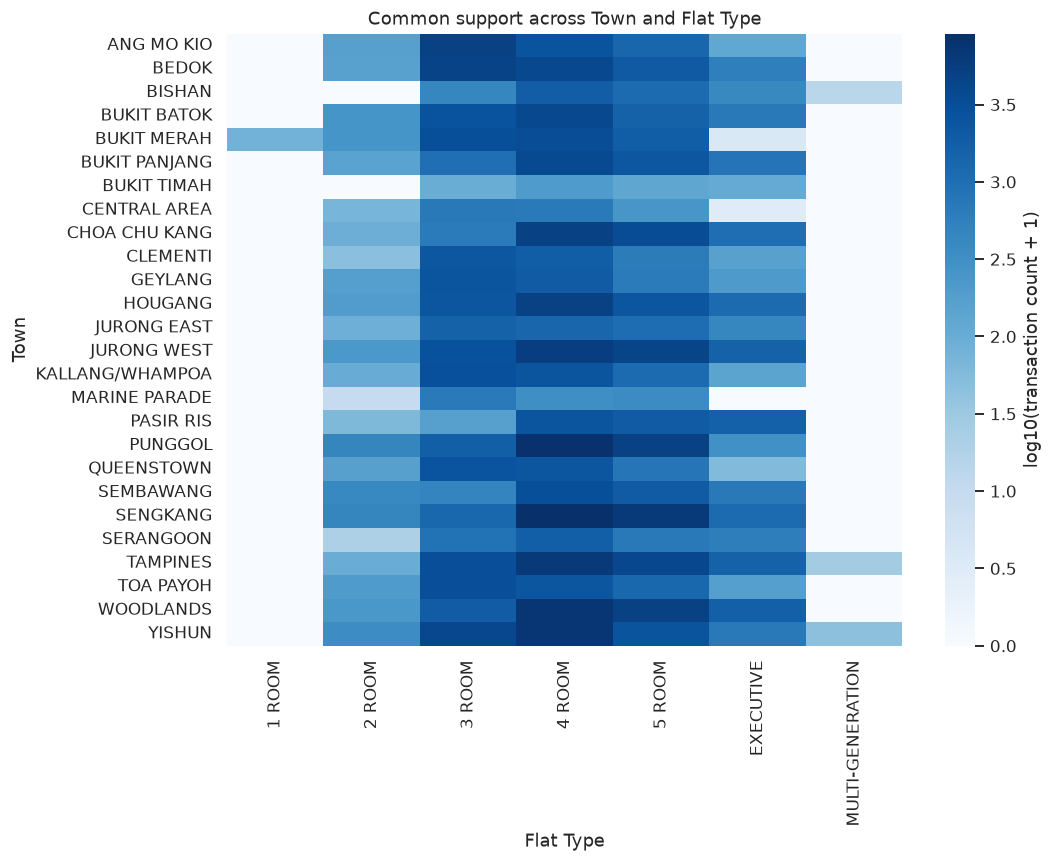


The smallest Flat Type groups are **1 ROOM (80 rows)** and **MULTI-GENERATION (84 rows)**. Their separate coefficients and test errors are too unstable for strong conclusions. No 2025 category is unseen in 2018–2024, so the chronological test does not require inventing a coefficient for a new label.


In [18]:
imbalance_fields = ["town", "flat_type", "flat_model", "storey_range"]
imbalance_training = df.loc[df["transaction_year"].between(2018, 2024)]
imbalance_test = df.loc[df["transaction_year"].eq(2025)]
summary_rows = []
shift_rows = []

for field in imbalance_fields:
    counts = df[field].value_counts()
    train_share = imbalance_training[field].value_counts(normalize=True)
    test_share = imbalance_test[field].value_counts(normalize=True)
    levels = counts.index.union(test_share.index)
    shift = 100 * (test_share.reindex(levels, fill_value=0)
                   - train_share.reindex(levels, fill_value=0))
    summary_rows.append({
        "field": field,
        "levels": len(counts),
        "smallest_group": counts.min(),
        "largest_group": counts.max(),
        "levels_below_200": counts.lt(200).sum(),
        "unseen_in_2025": (~levels.isin(train_share.index)).sum(),
        "distribution_shift_pct": 50 * shift.abs().sum() / 100,
    })
    for level in levels:
        shift_rows.append({"field": field, "level": level, "shift_pp": shift[level]})

imbalance_summary = pd.DataFrame(summary_rows).set_index("field")
low_support = pd.concat([
    df[field].value_counts().loc[lambda s: s.lt(200)].rename_axis("level").reset_index(name="rows").assign(field=field)
    for field in imbalance_fields
], ignore_index=True).sort_values(["field", "rows"])
display(imbalance_summary)
display(low_support[["field", "level", "rows"]])

town_type_counts = pd.crosstab(df["town"], df["flat_type"])
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(np.log10(town_type_counts + 1), cmap="Blues", ax=ax,
            cbar_kws={"label": "log10(transaction count + 1)"})
ax.set(title="Common support across Town and Flat Type", xlabel="Flat Type", ylabel="Town")
plt.tight_layout()
plt.show()

display(Markdown(f"""
The smallest Flat Type groups are **1 ROOM ({df['flat_type'].eq('1 ROOM').sum():,} rows)** and **MULTI-GENERATION ({df['flat_type'].eq('MULTI-GENERATION').sum():,} rows)**. Their separate coefficients and test errors are too unstable for strong conclusions. No 2025 category is unseen in 2018–2024, so the chronological test does not require inventing a coefficient for a new label.
"""))

## 8. Descriptive context before modelling

The snapshot covers every expected month from January 2017 through December 2025. The correlation table is a screening device: it reports marginal associations before controls and includes one-hot category indicators. The target-derived address encoding is shown on the common 2018–2025 subset but is not independent evidence of causation.

In [19]:
monthly = df.groupby("transaction_date").agg(
    transactions=("resale_price", "size"),
    median_price=("resale_price", "median"),
    median_area=("floor_area_sqm", "median"),
    median_remaining_lease=("remaining_lease_years", "median"),
)
expected_months = pd.date_range("2017-01-01", "2025-12-01", freq="MS")
display(pd.Series({
    "observed_months": len(monthly),
    "expected_months": len(expected_months),
    "missing_months": len(expected_months.difference(monthly.index)),
    "month_index_min": df["month_index"].min(),
    "month_index_max": df["month_index"].max(),
}, name="Time coverage").to_frame())
display(monthly.head())
display(monthly.tail())

,Time coverage
observed_months,108
expected_months,108
missing_months,0
month_index_min,0
month_index_max,107


,transactions,median_price,median_area,median_remaining_lease
transaction_date,,,,
2017-01-01,1185,405000.000,95.000,71.667
2017-02-01,1085,415000.000,96.000,74.500
2017-03-01,1903,415000.000,95.000,74.583
2017-04-01,1839,408000.000,95.000,74.000
2017-05-01,1980,410000.000,96.000,74.583


,transactions,median_price,median_area,median_remaining_lease
transaction_date,,,,
2025-08-01,2202,622000.000,93.000,71.667
2025-09-01,2174,645000.000,93.000,72.250
2025-10-01,1338,620000.000,93.000,70.625
2025-11-01,1658,618000.000,93.000,71.083
2025-12-01,2024,635000.000,93.000,71.083


In [20]:
continuous_features = [
    "floor_area_sqm", "remaining_lease_years", "storey_ordinal", "month_index"
]
association_sample = df.loc[address_encoding.index]
association_features = pd.concat([
    association_sample[continuous_features],
    one_hot.loc[association_sample.index],
    association_sample[["address_te"]],
], axis=1)
price_associations = pd.DataFrame({
    "pearson": association_features.corrwith(association_sample["resale_price"], method="pearson"),
    "spearman": association_features.corrwith(association_sample["resale_price"], method="spearman"),
})
price_associations["absolute_pearson"] = price_associations["pearson"].abs()
display(price_associations.nlargest(15, "absolute_pearson").drop(columns="absolute_pearson"))

,pearson,spearman
address_te,0.807,0.788
floor_area_sqm,0.577,0.613
flat_type_3 ROOM,-0.461,-0.521
month_index,0.397,0.418
storey_ordinal,0.341,0.247
flat_type_EXECUTIVE,0.309,0.299
remaining_lease_years,0.306,0.328
flat_type_5 ROOM,0.304,0.336
flat_model_New Generation,-0.282,-0.315
flat_model_Maisonette,0.231,0.206


## 9. Sequential hedonic regression

The outcome is `log(resale_price)`. Month indicators absorb market-wide changes across observed months; log area is an elasticity; storey intervals enter as categories; and remaining lease is measured in ten-year units centred at 70 years. Standard errors are clustered by Town + Street + Block.

`MULTI-GENERATION` Flat Type and `Multi Generation` Flat Model identify the same records. The redundant model indicator is removed so every fitted design is full rank. BEDOK, 4 ROOM, Model A, and 01 TO 03 are the reference categories.

In [21]:
import statsmodels.api as sm
import patsy
from IPython.display import Markdown


def regression_data(data):
    """Create readable regression fields without changing the supplied sample."""
    columns = list(raw.columns) + ["transaction_year", "month_index", "storey_ordinal", "remaining_lease_years"]
    result = data[columns].copy()
    for column in ["town", "flat_type", "flat_model", "storey_range", "month", "block", "street_name"]:
        result[column] = result[column].astype(str)
    result["log_price"] = np.log(result["resale_price"])
    result["log_area"] = np.log(result["floor_area_sqm"])
    result["lease_10"] = (result["remaining_lease_years"] - 70) / 10
    result["time_years"] = (result["month_index"] - 48) / 12
    result["calendar_month"] = result["month_index"].mod(12) + 1
    result["building_id"] = result[["town", "street_name", "block"]].agg(" | ".join, axis=1)
    return result


hedonic = regression_data(df)
TOWN = "C(town, Treatment(reference='BEDOK'))"
TIME = "C(month)"
TYPE = "C(flat_type, Treatment(reference='4 ROOM'))"
MODEL = "C(flat_model, Treatment(reference='Model A'))"
STOREY = "C(storey_range, Treatment(reference='01 TO 03'))"
REDUNDANT_MODEL = f"{MODEL}[T.Multi Generation]"


def fit_hedonic(formula, data, clustered=True):
    """Fit OLS, omitting the model indicator absorbed by its identical flat type."""
    outcome, design = patsy.dmatrices(formula, data, return_type="dataframe")
    design_info = design.design_info
    if REDUNDANT_MODEL in design.columns:
        design = design.drop(columns=REDUNDANT_MODEL)
    model = sm.OLS(outcome.iloc[:, 0], design)
    if clustered:
        fit = model.fit(method="qr", cov_type="cluster", use_t=True,
                        cov_kwds={"groups": data.loc[design.index, "building_id"]})
    else:
        fit = model.fit(method="qr")
    assert fit.model.rank == design.shape[1]
    return fit, design_info


def predict_log(fit, design_info, data):
    design = patsy.build_design_matrices([design_info], data, return_type="dataframe")[0]
    return pd.Series(fit.predict(design[fit.params.index]), index=data.index)


display(pd.Series({
    "explanatory_rows": len(hedonic),
    "towns": hedonic["town"].nunique(),
    "registration_months": hedonic["month"].nunique(),
    "building_clusters": hedonic["building_id"].nunique(),
}, name="Regression sample").to_frame())

,Regression sample
explanatory_rows,221938
towns,26
registration_months,108
building_clusters,9670


In [22]:
formulas = {
    "M0": f"log_price ~ {TOWN}",
    "M1": f"log_price ~ {TOWN} + {TIME}",
    "M2": f"log_price ~ {TOWN} + {TIME} + log_area",
    "M3": f"log_price ~ {TOWN} + {TIME} + log_area + {TYPE} + {MODEL}",
    "M4": f"log_price ~ {TOWN} + {TIME} + log_area + {TYPE} + {MODEL} + {STOREY} + lease_10",
}
main_fits = {}
main_info = {}
for name, formula in formulas.items():
    main_fits[name], main_info[name] = fit_hedonic(formula, hedonic)

model_comparison = pd.DataFrame({
    name: {
        "rows": fit.nobs,
        "coefficients": len(fit.params),
        "adjusted_R2": fit.rsquared_adj,
        "in_sample_log_RMSE": np.sqrt(np.mean(fit.resid ** 2)),
    }
    for name, fit in main_fits.items()
}).T
assert model_comparison["rows"].eq(len(hedonic)).all()
display(model_comparison)

,rows,coefficients,adjusted_R2,in_sample_log_RMSE
M0,221938.000,26.000,0.084,0.332
M1,221938.000,133.000,0.276,0.295
M2,221938.000,134.000,0.746,0.175
M3,221938.000,159.000,0.837,0.140
M4,221938.000,176.000,0.918,0.099


### 9.1 Redundancy and coefficient dependence

The exact redundant indicator is removed before fitting. Standardized VIFs check dependence among the continuous terms; movement across M0–M4 is then used to show the substantive dependence between Town and the housing composition variables.

In [23]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_fields = ["log_area", "lease_10", "storey_ordinal", "time_years"]
vif_design = hedonic[vif_fields].apply(lambda s: (s - s.mean()) / s.std())
vif_design = sm.add_constant(vif_design)
continuous_vif = pd.Series(
    [variance_inflation_factor(vif_design.to_numpy(), i) for i in range(1, vif_design.shape[1])],
    index=vif_fields,
    name="VIF",
).to_frame()
display(continuous_vif)
display(Markdown(f"""
The design-rank check confirms that every fitted main model is full rank after the exact redundant indicator is removed. The largest continuous-term VIF is **{continuous_vif['VIF'].max():.2f}**. This does not make individual coefficients causal; the large movement of the area coefficient and Town premiums across control steps shows that the housing attributes remain substantively interrelated.
"""))

,VIF
log_area,1.025
lease_10,1.108
storey_ordinal,1.083
time_years,1.004



The design-rank check confirms that every fitted main model is full rank after the exact redundant indicator is removed. The largest continuous-term VIF is **1.11**. This does not make individual coefficients causal; the large movement of the area coefficient and Town premiums across control steps shows that the housing attributes remain substantively interrelated.


## 10. Main finding: the PASIR RIS premium reverses

Town coefficients are converted to percentage differences relative to BEDOK. The critical comparison is M0–M4, fitted on exactly the same rows.

The sequence provides a direct answer: PASIR RIS first appears more expensive than BEDOK, but the sign reverses when floor area is added. The calculation below reports how much of the M1-to-M4 coefficient movement occurs at each step. Because sequential attribution depends on control order, the percentage is descriptive rather than a causal decomposition.

A common-segment sensitivity then restricts the data to 4 ROOM, Model A transactions, which are well represented in both Towns. This checks whether the adjusted result is merely extrapolation between different flat categories.

,M0_pct,M4_pct,change_pp
town,,,
PASIR RIS,25.942,-12.473,-38.415
PUNGGOL,17.389,-17.180,-34.569
SENGKANG,13.773,-19.288,-33.061
SEMBAWANG,7.360,-24.129,-31.489
CHOA CHU KANG,5.424,-24.658,-30.082
BISHAN,50.186,20.916,-29.271
BUKIT PANJANG,7.175,-18.890,-26.065
WOODLANDS,1.502,-23.172,-24.675
TAMPINES,19.795,-4.125,-23.920


,model,control_added,premium_pct,change_from_previous_pp
0,M0,Town only,25.942,NaN
1,M1,Registration month,26.497,0.555
2,M2,Log floor area,-6.246,-32.743
3,M3,Flat Type and Model,-10.239,-3.993
4,M4,Storey and lease,-12.473,-2.234


,transactions,median_price,median_area,median_lease,five_room_share_pct,executive_share_pct
town,,,,,,
BEDOK,11555,428000.000,88.000,59.583,18.122,4.976
PASIR RIS,6393,565000.000,122.000,71.750,31.550,25.575


,4 ROOM Model A rows
town,
BEDOK,1175
PASIR RIS,2376


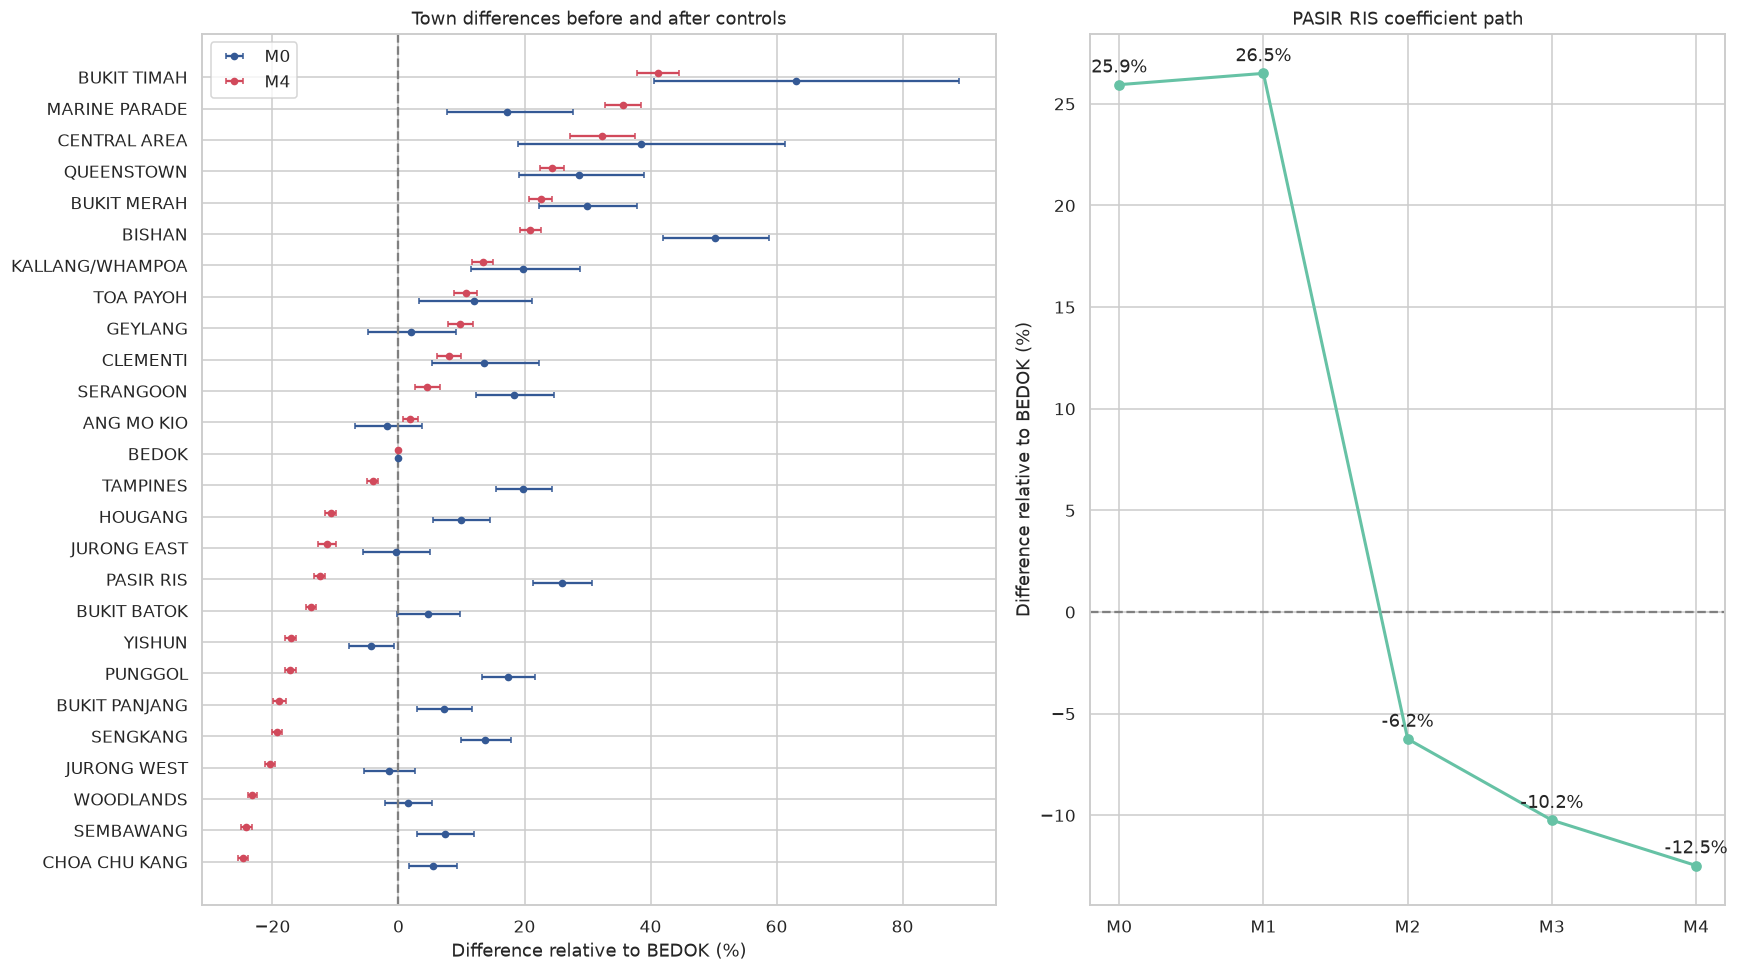


**Conclusion.** PASIR RIS changes from **26.5%** after calendar controls to **-12.5%** after all controls. Adding floor area alone moves the estimate by **-32.7 percentage points** and produces the sign reversal. Under this control order, that step represents **84.0%** of the total M1-to-M4 movement. PASIR RIS has a median floor area of **122 sqm**, versus **88 sqm** in BEDOK.

The common 4 ROOM, Model A segment contains **2,376 PASIR RIS** and **1,175 BEDOK** transactions. Within this more comparable segment, the adjusted PASIR RIS difference is **-16.1%** (95% CI **-18.0% to -14.2%**). The evidence therefore supports a **housing-composition reversal dominated by floor area**, rather than a positive PASIR RIS location premium. This is an omitted-variable reversal; it is not presented as Simpson's paradox or as a causal location effect.


In [24]:
def town_effects(fit):
    confidence = fit.conf_int()
    rows = [{"town": "BEDOK", "premium_pct": 0., "low_pct": 0., "high_pct": 0.}]
    for term in fit.params.index:
        if term.startswith(TOWN + "[T."):
            rows.append({
                "town": term.split("[T.")[1][:-1],
                "premium_pct": 100 * np.expm1(fit.params[term]),
                "low_pct": 100 * np.expm1(confidence.loc[term, 0]),
                "high_pct": 100 * np.expm1(confidence.loc[term, 1]),
            })
    return pd.DataFrame(rows).set_index("town")


regional_effects = {name: town_effects(fit) for name, fit in main_fits.items()}
regional_path = pd.DataFrame({name: table["premium_pct"] for name, table in regional_effects.items()})
regional_change = pd.DataFrame({
    "M0_pct": regional_path["M0"],
    "M4_pct": regional_path["M4"],
})
regional_change["change_pp"] = regional_change["M4_pct"] - regional_change["M0_pct"]
display(regional_change.reindex(regional_change["change_pp"].abs().sort_values(ascending=False).index).head(10))

pasir_path = regional_path.loc["PASIR RIS", ["M0", "M1", "M2", "M3", "M4"]]
pasir_steps = pd.DataFrame({
    "model": pasir_path.index,
    "control_added": ["Town only", "Registration month", "Log floor area", "Flat Type and Model", "Storey and lease"],
    "premium_pct": pasir_path.values,
})
pasir_steps["change_from_previous_pp"] = pasir_steps["premium_pct"].diff()
composition_change = pasir_path["M4"] - pasir_path["M1"]
area_change = pasir_path["M2"] - pasir_path["M1"]
area_share_of_movement = abs(area_change / composition_change) * 100
display(pasir_steps)

focus_profiles = hedonic.loc[hedonic["town"].isin(["BEDOK", "PASIR RIS"])].groupby("town").agg(
    transactions=("resale_price", "size"),
    median_price=("resale_price", "median"),
    median_area=("floor_area_sqm", "median"),
    median_lease=("remaining_lease_years", "median"),
    five_room_share_pct=("flat_type", lambda s: 100 * s.eq("5 ROOM").mean()),
    executive_share_pct=("flat_type", lambda s: 100 * s.eq("EXECUTIVE").mean()),
)
display(focus_profiles)

common_segment = hedonic.loc[
    hedonic["flat_type"].eq("4 ROOM") & hedonic["flat_model"].eq("Model A")
]
common_formula = f"log_price ~ {TOWN} + {TIME} + log_area + {STOREY} + lease_10"
common_fit, _ = fit_hedonic(common_formula, common_segment)
common_term = TOWN + "[T.PASIR RIS]"
common_ci = common_fit.conf_int().loc[common_term]
common_effect = 100 * np.expm1(common_fit.params[common_term])
common_low, common_high = 100 * np.expm1(common_ci)
common_counts = common_segment.groupby("town").size().reindex(["BEDOK", "PASIR RIS"])
display(common_counts.rename("4 ROOM Model A rows").to_frame())

order = regional_effects["M4"]["premium_pct"].sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(16, 9), gridspec_kw={"width_ratios": [1.25, 1]})
for name, offset, color in [("M0", -.12, "#345995"), ("M4", .12, "#d1495b")]:
    effects = regional_effects[name].reindex(order)
    y = np.arange(len(order)) + offset
    axes[0].errorbar(
        effects["premium_pct"], y,
        xerr=[effects["premium_pct"] - effects["low_pct"], effects["high_pct"] - effects["premium_pct"]],
        fmt="o", markersize=4, capsize=2, color=color, label=name,
    )
axes[0].set_yticks(np.arange(len(order)), order)
axes[0].axvline(0, color="gray", linestyle="--")
axes[0].set(title="Town differences before and after controls", xlabel="Difference relative to BEDOK (%)")
axes[0].legend()

axes[1].plot(pasir_steps["model"], pasir_steps["premium_pct"], marker="o", linewidth=2)
axes[1].axhline(0, color="gray", linestyle="--")
for x, y in zip(pasir_steps["model"], pasir_steps["premium_pct"]):
    axes[1].annotate(f"{y:.1f}%", (x, y), xytext=(0, 8), textcoords="offset points", ha="center")
axes[1].set(title="PASIR RIS coefficient path", ylabel="Difference relative to BEDOK (%)")
plt.tight_layout()
plt.show()

display(Markdown(f"""
**Conclusion.** PASIR RIS changes from **{pasir_path['M1']:.1f}%** after calendar controls to **{pasir_path['M4']:.1f}%** after all controls. Adding floor area alone moves the estimate by **{area_change:.1f} percentage points** and produces the sign reversal. Under this control order, that step represents **{area_share_of_movement:.1f}%** of the total M1-to-M4 movement. PASIR RIS has a median floor area of **{focus_profiles.loc['PASIR RIS', 'median_area']:.0f} sqm**, versus **{focus_profiles.loc['BEDOK', 'median_area']:.0f} sqm** in BEDOK.

The common 4 ROOM, Model A segment contains **{common_counts['PASIR RIS']:,} PASIR RIS** and **{common_counts['BEDOK']:,} BEDOK** transactions. Within this more comparable segment, the adjusted PASIR RIS difference is **{common_effect:.1f}%** (95% CI **{common_low:.1f}% to {common_high:.1f}%**). The evidence therefore supports a **housing-composition reversal dominated by floor area**, rather than a positive PASIR RIS location premium. This is an omitted-variable reversal; it is not presented as Simpson's paradox or as a causal location effect.
"""))

### 10.1 Geographic view of the same result

The two maps display M0 and M4 on the same colour scale. They visualize the coefficient change using planning-area proxies; they do not locate individual transactions or redefine HDB Town boundaries.

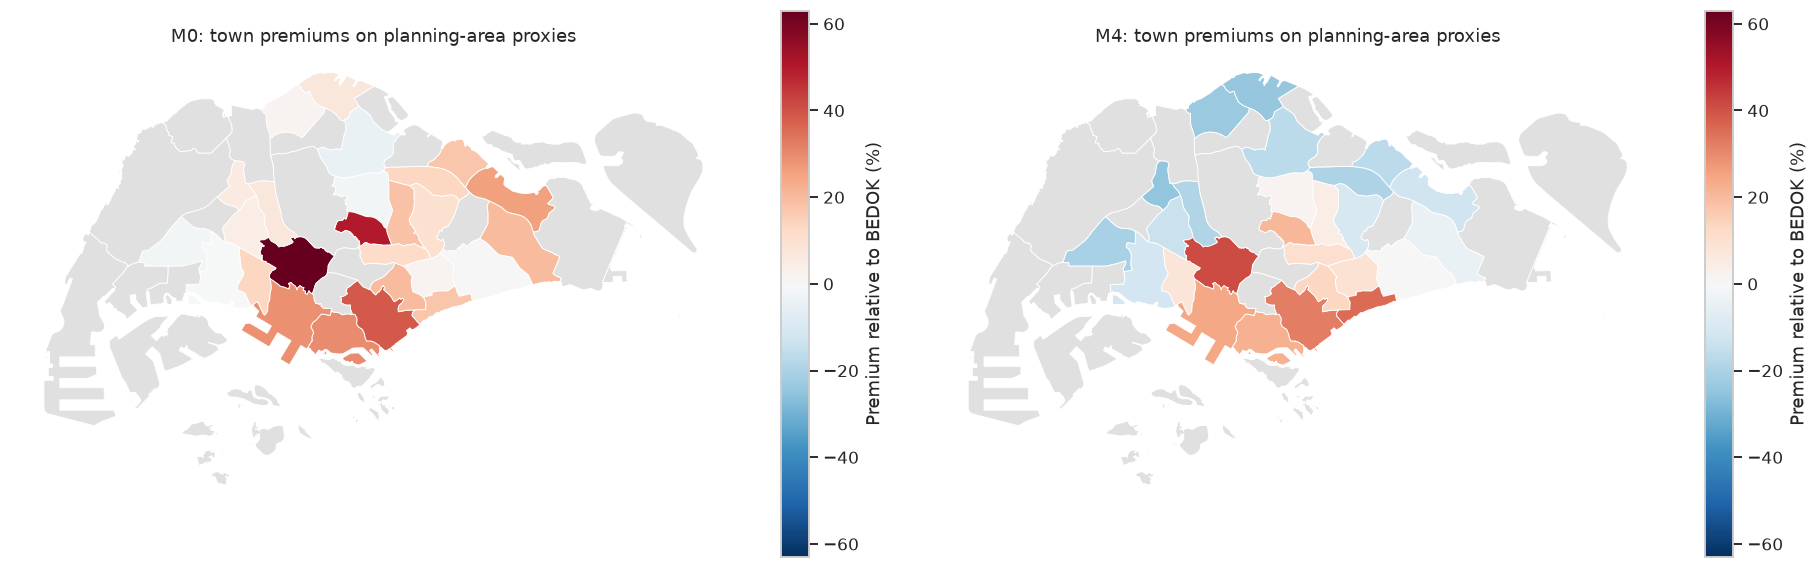

In [25]:
premium_map = town_boundaries.merge(regional_path[["M0", "M4"]], left_on="map_town", right_index=True, how="left")
limit = np.abs(regional_path[["M0", "M4"]].to_numpy()).max()
fig, axes = plt.subplots(1, 2, figsize=(17, 8))
for name, ax in zip(["M0", "M4"], axes):
    premium_map.plot(column=name, cmap="RdBu_r", vmin=-limit, vmax=limit,
                     legend=True, ax=ax, edgecolor="white", linewidth=.6,
                     missing_kwds={"color": "#e0e0e0"},
                     legend_kwds={"label": "Premium relative to BEDOK (%)", "shrink": .65})
    ax.set_title(f"{name}: town premiums on planning-area proxies")
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## 11. What the main controls mean

The control variables are necessary to make Town comparisons more comparable. Their coefficients remain conditional associations. Flat Model is retained as a nuisance control but is not ranked individually because several labels have limited support and overlap strongly with Flat Type.

,estimate,low,high,unit
effect,,,,
Area elasticity,0.811,0.778,0.844,% price per 1% area
Ten-year remaining-lease difference,10.390,10.153,10.628,% price per 10 lease years


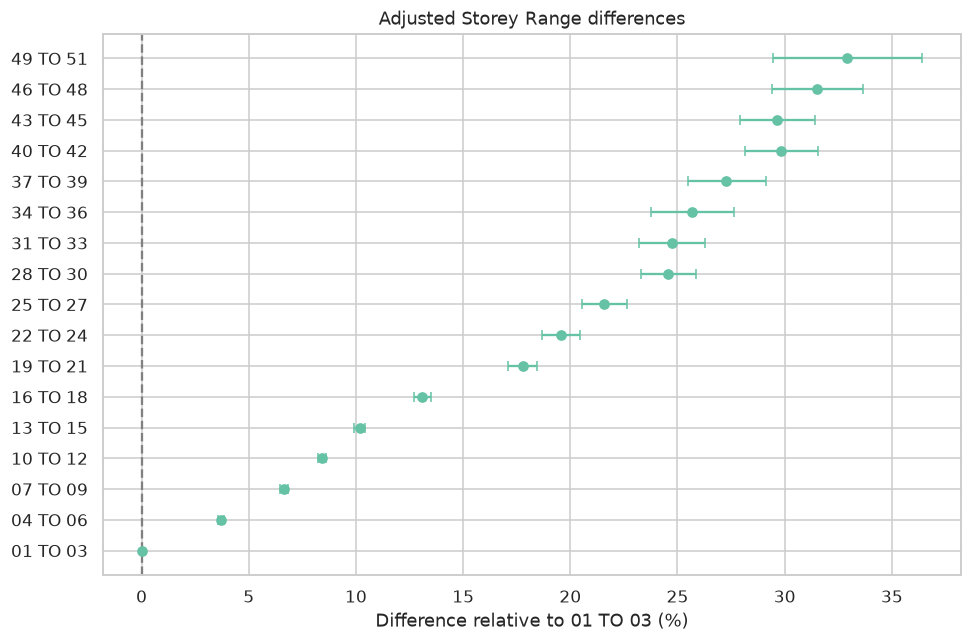

In [26]:
main = main_fits["M4"]
confidence = main.conf_int()
key_effects = pd.DataFrame({
    "effect": ["Area elasticity", "Ten-year remaining-lease difference"],
    "estimate": [main.params["log_area"], 100 * np.expm1(main.params["lease_10"])],
    "low": [confidence.loc["log_area", 0], 100 * np.expm1(confidence.loc["lease_10", 0])],
    "high": [confidence.loc["log_area", 1], 100 * np.expm1(confidence.loc["lease_10", 1])],
    "unit": ["% price per 1% area", "% price per 10 lease years"],
}).set_index("effect")
display(key_effects)

storey_rows = [{"storey_range": "01 TO 03", "difference_pct": 0., "low_pct": 0., "high_pct": 0.}]
for term in main.params.index:
    if term.startswith(STOREY + "[T."):
        label = term.split("[T.")[1][:-1]
        storey_rows.append({
            "storey_range": label,
            "difference_pct": 100 * np.expm1(main.params[term]),
            "low_pct": 100 * np.expm1(confidence.loc[term, 0]),
            "high_pct": 100 * np.expm1(confidence.loc[term, 1]),
        })
storey_effects = pd.DataFrame(storey_rows).set_index("storey_range").reindex(storey_order)
fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(storey_effects))
ax.errorbar(
    storey_effects["difference_pct"], y,
    xerr=[storey_effects["difference_pct"] - storey_effects["low_pct"],
          storey_effects["high_pct"] - storey_effects["difference_pct"]],
    fmt="o", capsize=3,
)
ax.set_yticks(y, storey_effects.index)
ax.axvline(0, color="gray", linestyle="--")
ax.set(title="Adjusted Storey Range differences", xlabel="Difference relative to 01 TO 03 (%)")
plt.tight_layout()
plt.show()

## 12. Diagnostics and decision sensitivity

Residual diagnostics assess functional-form limitations. The preparation sensitivity refits M4 after deduplication, restoration of the lease flags, and ordinal rather than categorical Storey Range. The main Town conclusion is considered robust only if these reasonable alternatives do not materially change Town coefficients.

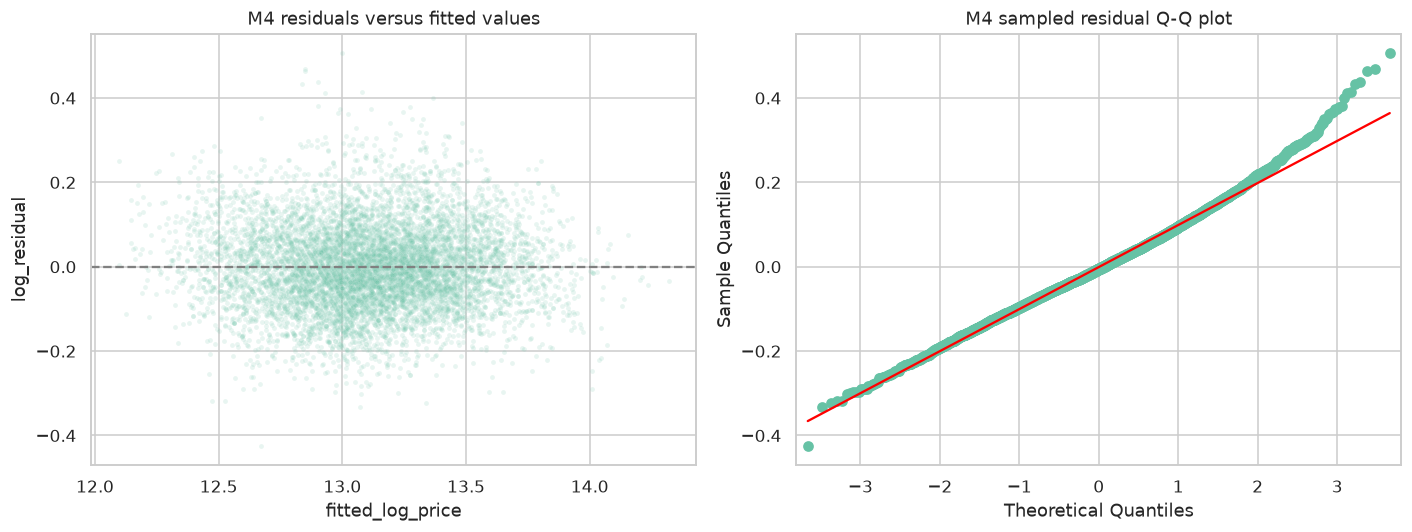

,rows,PASIR_RIS_pct,maximum_Town_change_vs_main_pp
variant,,,
Main,221938.000,-12.473,0.000
Deduplicated,221629.000,-12.471,0.093
Lease flags retained,222066.000,-12.472,0.012
Ordinal storey,221938.000,-12.433,0.358



The largest Town-coefficient change across these alternatives is **0.36 percentage points**. PASIR RIS remains negative in every specification, so duplicate handling, the small lease exclusion, and Storey representation do not explain the sign reversal.


In [27]:
diagnostics = pd.DataFrame({
    "fitted_log_price": main.fittedvalues,
    "log_residual": main.resid,
}).sample(8000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=diagnostics, x="fitted_log_price", y="log_residual", alpha=.15, s=10, ax=axes[0])
axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set_title("M4 residuals versus fitted values")
sm.qqplot(diagnostics["log_residual"], line="s", ax=axes[1])
axes[1].set_title("M4 sampled residual Q-Q plot")
plt.tight_layout()
plt.show()

all_valid = regression_data(pd.concat([df, lease_excluded]).sort_index())
explanatory_variants = {
    "Main": (formulas["M4"], hedonic),
    "Deduplicated": (formulas["M4"], hedonic.loc[~hedonic.duplicated(subset=list(raw.columns))]),
    "Lease flags retained": (formulas["M4"], all_valid),
    "Ordinal storey": (formulas["M4"].replace(STOREY, "storey_ordinal"), hedonic),
}
sensitivity_rows = []
for name, (formula, sample) in explanatory_variants.items():
    fit = main if name == "Main" else fit_hedonic(formula, sample)[0]
    premiums = town_effects(fit)["premium_pct"]
    sensitivity_rows.append({
        "variant": name,
        "rows": fit.nobs,
        "PASIR_RIS_pct": premiums["PASIR RIS"],
        "maximum_Town_change_vs_main_pp": (premiums - regional_path["M4"]).abs().max(),
    })
sensitivity_table = pd.DataFrame(sensitivity_rows).set_index("variant")
display(sensitivity_table)
display(Markdown(f"""
The largest Town-coefficient change across these alternatives is **{sensitivity_table['maximum_Town_change_vs_main_pp'].max():.2f} percentage points**. PASIR RIS remains negative in every specification, so duplicate handling, the small lease exclusion, and Storey representation do not explain the sign reversal.
"""))

## 13. Out-of-time preparation comparison

Use 2018–2023 for development, 2024 for time-trend selection, and 2018–2024 for final training. Every model is tested on the same cleaned 2025 records. All models use OLS; the variants change only data preparation.

| Variant | Preparation represented |
|---|---|
| B0 minimal/source-like | Mandatory parsing and one-hot encoding; raw price/area, ordinal storey, linear lease/time; lease flags retained in training |
| B1 + cleaning | B0 after the evidence-based lease exclusion |
| B2 + feature preparation | Log area, Flat Model, categorical storey, and quadratic lease; raw-price OLS |
| B3 + log target | B2 with log-price OLS and training-residual smearing |
| B4 + historical address | B3 plus leakage-controlled hierarchical address encoding |

B0 is minimally processed rather than literally unparsed because OLS cannot consume date and lease strings. The comparison reports MAE, RMSE, signed error, equal-Town macro-MAE, and worst-Town MAE.

,period,years,rows
0,development,2018–2023,148595
1,validation,2024,27812
2,final training,2018–2024,176407
3,test,2025,25022


,MAE_SGD,RMSE_SGD,mean_error_SGD,Town_macro_MAE_SGD,worst_Town_MAE_SGD
trend,,,,,
linear,44121.562,59348.186,-9751.660,48614.120,74136.259
quadratic,67116.140,84994.796,56244.128,75894.447,134461.405


Selected using 2024 validation MAE: linear


,training_rows,test_rows,validation_MAE_SGD,MAE_SGD,RMSE_SGD,mean_error_SGD,Town_macro_MAE_SGD,worst_Town_MAE_SGD
variant,,,,,,,,
B0 minimal/source-like,176473,25022,57143.431,59792.189,85594.533,-17146.355,73372.220,181874.249
B1 + cleaning,176407,25022,57145.119,59794.424,85597.052,-17154.345,73374.075,181874.642
B2 + prepared features,176407,25022,53965.510,56987.795,81056.374,-16721.830,68034.265,142658.774
B3 + log target,176407,25022,44121.562,47230.855,63324.020,331.294,51237.515,85004.255
B4 + historical address,176407,25022,42463.510,46308.805,62066.736,14611.065,48744.158,74307.401


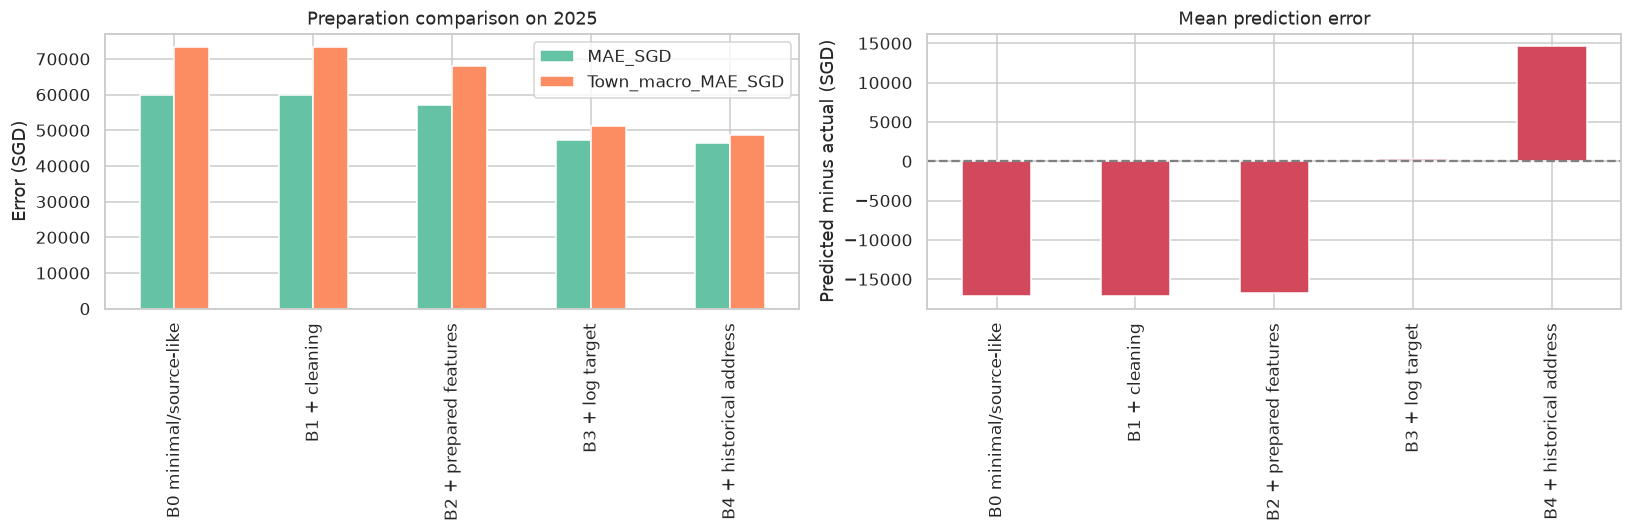


**Prediction conclusion.** Systematic preparation reduces 2025 MAE from **SGD 59,792** to **SGD 46,309**, a reduction of **22.6%**. Cleaning alone has almost no accuracy effect; the large improvement appears when the functional form and log target are prepared. B4 is more accurate overall but its signed error must be considered below.


In [28]:
forecast = hedonic.loc[hedonic["transaction_year"].ge(2018)].copy()
forecast["log_address_te"] = np.log(address_encoding.loc[forecast.index, "address_te"])
raw_forecast = all_valid.loc[all_valid["transaction_year"].ge(2018)].copy()

development = forecast.loc[forecast["transaction_year"].le(2023)]
validation = forecast.loc[forecast["transaction_year"].eq(2024)]
training = forecast.loc[forecast["transaction_year"].le(2024)]
test = forecast.loc[forecast["transaction_year"].eq(2025)]
raw_development = raw_forecast.loc[raw_forecast["transaction_year"].le(2023)]
raw_training = raw_forecast.loc[raw_forecast["transaction_year"].le(2024)]

for column in ["town", "flat_type", "flat_model", "storey_range"]:
    assert set(test[column]) <= set(training[column])
display(pd.DataFrame({
    "period": ["development", "validation", "final training", "test"],
    "years": ["2018–2023", "2024", "2018–2024", "2025"],
    "rows": [len(development), len(validation), len(training), len(test)],
}))


def price_scores(actual, predicted, towns):
    error = predicted - actual
    town_mae = error.abs().groupby(towns).mean()
    return {
        "MAE_SGD": error.abs().mean(),
        "RMSE_SGD": np.sqrt(np.mean(error ** 2)),
        "mean_error_SGD": error.mean(),
        "Town_macro_MAE_SGD": town_mae.mean(),
        "worst_Town_MAE_SGD": town_mae.max(),
    }


def predict_price(formula, fit_data, predict_data, log_target):
    fit, info = fit_hedonic(formula, fit_data, clustered=False)
    fitted = predict_log(fit, info, predict_data)
    if log_target:
        fitted = np.exp(fitted) * np.exp(fit.resid).mean()
    return fit, fitted


minimal_rhs = (
    f"{TOWN} + {TYPE} + floor_area_sqm + storey_ordinal "
    "+ remaining_lease_years + TIME_TERM"
)
prepared_rhs = (
    f"{TOWN} + {TYPE} + {MODEL} + log_area + {STOREY} "
    "+ lease_10 + I(lease_10 ** 2) + TIME_TERM"
)

trend_rows = []
for trend, term in {
    "linear": "time_years + C(calendar_month)",
    "quadratic": "time_years + I(time_years ** 2) + C(calendar_month)",
}.items():
    formula = "log_price ~ " + prepared_rhs.replace("TIME_TERM", term)
    _, predicted = predict_price(formula, development, validation, log_target=True)
    trend_rows.append({"trend": trend, **price_scores(
        validation["resale_price"], predicted, validation["town"]
    )})
trend_validation = pd.DataFrame(trend_rows).set_index("trend")
selected_trend = trend_validation["MAE_SGD"].idxmin()
time_term = {
    "linear": "time_years + C(calendar_month)",
    "quadratic": "time_years + I(time_years ** 2) + C(calendar_month)",
}[selected_trend]
display(trend_validation)
print(f"Selected using 2024 validation MAE: {selected_trend}")

pipeline_formulas = {
    "B0 minimal/source-like": "resale_price ~ " + minimal_rhs.replace("TIME_TERM", time_term),
    "B1 + cleaning": "resale_price ~ " + minimal_rhs.replace("TIME_TERM", time_term),
    "B2 + prepared features": "resale_price ~ " + prepared_rhs.replace("TIME_TERM", time_term),
    "B3 + log target": "log_price ~ " + prepared_rhs.replace("TIME_TERM", time_term),
    "B4 + historical address": "log_price ~ " + prepared_rhs.replace("TIME_TERM", time_term) + " + log_address_te",
}
development_sets = {
    "B0 minimal/source-like": raw_development,
    "B1 + cleaning": development,
    "B2 + prepared features": development,
    "B3 + log target": development,
    "B4 + historical address": development,
}
training_sets = {
    "B0 minimal/source-like": raw_training,
    "B1 + cleaning": training,
    "B2 + prepared features": training,
    "B3 + log target": training,
    "B4 + historical address": training,
}
log_variants = {"B3 + log target", "B4 + historical address"}
pipeline_predictions = pd.DataFrame(index=test.index)
pipeline_models = {}
result_rows = []

for name, formula in pipeline_formulas.items():
    _, validation_prediction = predict_price(
        formula, development_sets[name], validation, name in log_variants
    )
    fit, test_prediction = predict_price(
        formula, training_sets[name], test, name in log_variants
    )
    pipeline_models[name] = fit
    pipeline_predictions[name] = test_prediction
    result_rows.append({
        "variant": name,
        "training_rows": len(training_sets[name]),
        "test_rows": len(test),
        "validation_MAE_SGD": np.mean(abs(validation_prediction - validation["resale_price"])),
        **price_scores(test["resale_price"], test_prediction, test["town"]),
    })

pipeline_results = pd.DataFrame(result_rows).set_index("variant")
assert pipeline_results["test_rows"].eq(len(test)).all()
display(pipeline_results)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
pipeline_results[["MAE_SGD", "Town_macro_MAE_SGD"]].plot.bar(ax=axes[0])
axes[0].set(title="Preparation comparison on 2025", xlabel="", ylabel="Error (SGD)")
pipeline_results["mean_error_SGD"].plot.bar(ax=axes[1], color="#d1495b")
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set(title="Mean prediction error", xlabel="", ylabel="Predicted minus actual (SGD)")
plt.tight_layout()
plt.show()

minimal_mae = pipeline_results.loc["B0 minimal/source-like", "MAE_SGD"]
prepared_mae = pipeline_results.loc["B4 + historical address", "MAE_SGD"]
display(Markdown(f"""
**Prediction conclusion.** Systematic preparation reduces 2025 MAE from **SGD {minimal_mae:,.0f}** to **SGD {prepared_mae:,.0f}**, a reduction of **{100 * (1 - prepared_mae / minimal_mae):.1f}%**. Cleaning alone has almost no accuracy effect; the large improvement appears when the functional form and log target are prepared. B4 is more accurate overall but its signed error must be considered below.
"""))

### 13.1 Uneven errors and imbalance mitigation

Overall MAE weights each transaction equally, so high-volume Towns influence it more. First compare B0 and B4 within Town and Flat Type. Then fit B4 with inverse-Town-frequency weights. This weighted model gives each Town equal total influence and directly tests whether transaction imbalance changes reliability. It changes the estimand, so both results are reported.

In [29]:
group_rows = []
for grouping in ["town", "flat_type"]:
    for group, part in test.groupby(grouping):
        for variant in ["B0 minimal/source-like", "B4 + historical address"]:
            error = pipeline_predictions.loc[part.index, variant] - part["resale_price"]
            group_rows.append({
                "grouping": grouping,
                "group": group,
                "rows": len(part),
                "variant": variant,
                "MAE_SGD": error.abs().mean(),
            })
group_errors = pd.DataFrame(group_rows).pivot(
    index=["grouping", "group", "rows"], columns="variant", values="MAE_SGD"
).reset_index()
group_errors["change_SGD"] = (
    group_errors["B4 + historical address"] - group_errors["B0 minimal/source-like"]
)
supported_groups = group_errors.loc[group_errors["rows"].ge(100)]
display(pd.concat([
    supported_groups.nsmallest(6, "change_SGD"),
    supported_groups.nlargest(6, "change_SGD"),
]).sort_values("change_SGD"))


def fit_weighted(formula, data, weights):
    outcome, design = patsy.dmatrices(formula, data, return_type="dataframe")
    info = design.design_info
    if REDUNDANT_MODEL in design.columns:
        design = design.drop(columns=REDUNDANT_MODEL)
    fit = sm.WLS(outcome.iloc[:, 0], design, weights=weights.loc[design.index]).fit()
    assert fit.model.rank == design.shape[1]
    return fit, info


town_frequency = training.groupby("town")["town"].transform("size")
town_weights = len(training) / (training["town"].nunique() * town_frequency)
balanced_fit, balanced_info = fit_weighted(
    pipeline_formulas["B4 + historical address"], training, town_weights
)
balanced_log = predict_log(balanced_fit, balanced_info, test)
balanced_smearing = np.average(
    np.exp(balanced_fit.resid), weights=town_weights.loc[balanced_fit.resid.index]
)
balanced_prediction = np.exp(balanced_log) * balanced_smearing

balance_results = pd.DataFrame({
    "Transaction-weighted B4": price_scores(
        test["resale_price"], pipeline_predictions["B4 + historical address"], test["town"]
    ),
    "Equal-Town weighted B4": price_scores(
        test["resale_price"], balanced_prediction, test["town"]
    ),
}).T
display(balance_results)

macro_reduction = (
    balance_results.loc["Transaction-weighted B4", "Town_macro_MAE_SGD"]
    - balance_results.loc["Equal-Town weighted B4", "Town_macro_MAE_SGD"]
)
bias_before = balance_results.loc["Transaction-weighted B4", "mean_error_SGD"]
bias_after = balance_results.loc["Equal-Town weighted B4", "mean_error_SGD"]
display(Markdown(f"""
**Imbalance conclusion.** Equal-Town weighting reduces Town macro-MAE by **SGD {macro_reduction:,.0f}** and changes mean overprediction from **SGD {bias_before:,.0f}** to **SGD {bias_after:,.0f}**. Unequal Town volume therefore affects predictive reliability. Transaction-weighted B4 answers performance for the average recorded sale; equal-Town B4 is preferable only when every Town should contribute equally to the objective.
"""))

variant,grouping,group,rows,B0 minimal/source-like,B4 + historical address,change_SGD
14,town,CENTRAL AREA,172,181874.249,50469.485,-131404.764
30,town,TOA PAYOH,1060,117764.327,58245.844,-59518.483
25,town,QUEENSTOWN,603,115739.212,62951.767,-52787.445
16,town,CLEMENTI,549,105017.902,62642.144,-42375.758
21,town,KALLANG/WHAMPOA,792,97442.505,58915.414,-38527.091
9,town,BISHAN,375,90617.343,53701.953,-36915.390
24,town,PUNGGOL,1536,44580.853,40160.985,-4419.867
8,town,BEDOK,1206,43784.561,42828.806,-955.755
15,town,CHOA CHU KANG,1026,36166.164,35381.721,-784.443
20,town,JURONG WEST,1588,41517.487,41418.444,-99.042


,MAE_SGD,RMSE_SGD,mean_error_SGD,Town_macro_MAE_SGD,worst_Town_MAE_SGD
Transaction-weighted B4,46308.805,62066.736,14611.065,48744.158,74307.401
Equal-Town weighted B4,46069.913,61495.809,7506.570,47271.557,69287.727



**Imbalance conclusion.** Equal-Town weighting reduces Town macro-MAE by **SGD 1,473** and changes mean overprediction from **SGD 14,611** to **SGD 7,507**. Unequal Town volume therefore affects predictive reliability. Transaction-weighted B4 answers performance for the average recorded sale; equal-Town B4 is preferable only when every Town should contribute equally to the objective.


### 13.2 Should valid price tails be removed?

Fit the same log-price specification with and without a training-only price-IQR restriction. Ordinal Storey is used in both versions because trimming removes the highest Storey category from training. The unchanged 2025 test set still includes expensive transactions.

In [30]:
price_q1, price_q3 = training["resale_price"].quantile([.25, .75])
price_upper = price_q3 + 1.5 * (price_q3 - price_q1)
tail_formula = pipeline_formulas["B3 + log target"].replace(STOREY, "storey_ordinal")
tail_training_sets = {
    "All training prices": training,
    "Training prices within IQR fence": training.loc[training["resale_price"].le(price_upper)],
}
tail_rows = []
for variant, sample in tail_training_sets.items():
    _, predicted = predict_price(tail_formula, sample, test, log_target=True)
    for test_group, mask in {
        "All test records": pd.Series(True, index=test.index),
        "Above training IQR fence": test["resale_price"].gt(price_upper),
    }.items():
        error = predicted.loc[mask] - test.loc[mask, "resale_price"]
        tail_rows.append({
            "training_policy": variant,
            "test_group": test_group,
            "test_rows": int(mask.sum()),
            "MAE_SGD": error.abs().mean(),
            "mean_error_SGD": error.mean(),
        })
tail_results = pd.DataFrame(tail_rows)
display(tail_results)

tail_wide = tail_results.pivot(index="test_group", columns="training_policy", values="MAE_SGD")
tail_increase = (
    tail_wide.loc["Above training IQR fence", "Training prices within IQR fence"]
    - tail_wide.loc["Above training IQR fence", "All training prices"]
)
display(Markdown(f"""
**Tail conclusion.** Removing high-price training records worsens MAE on expensive 2025 transactions by **SGD {tail_increase:,.0f}**. These prices represent a valid housing segment, so they remain in the prepared dataset even if trimming slightly changes an aggregate metric.
"""))

,training_policy,test_group,test_rows,MAE_SGD,mean_error_SGD
0,All training prices,All test records,25022,47377.724,296.287
1,All training prices,Above training IQR fence,1904,94743.324,-45758.322
2,Training prices within IQR fence,All test records,25022,47265.977,-1655.660
3,Training prices within IQR fence,Above training IQR fence,1904,98759.505,-50920.914



**Tail conclusion.** Removing high-price training records worsens MAE on expensive 2025 transactions by **SGD 4,016**. These prices represent a valid housing segment, so they remain in the prepared dataset even if trimming slightly changes an aggregate metric.


## 14. Conclusions

The notebook now supports one connected argument. The code below inserts the final values from this run.

In [31]:
pasir_m0 = regional_path.loc["PASIR RIS", "M0"]
pasir_m4 = regional_path.loc["PASIR RIS", "M4"]
cleaning_change = (
    pipeline_results.loc["B1 + cleaning", "MAE_SGD"]
    - pipeline_results.loc["B0 minimal/source-like", "MAE_SGD"]
)

display(Markdown(f"""
1. **The apparent PASIR RIS premium is mainly a composition effect.** Its estimated difference relative to BEDOK changes from **{pasir_m0:.1f}%** in M0 to **{pasir_m4:.1f}%** in M4. The sign reverses as soon as floor area is added, and that step accounts for **{area_share_of_movement:.1f}%** of the M1-to-M4 movement under the stated order. PASIR RIS flats sold in this sample are substantially larger. The result remains negative (**{common_effect:.1f}%**) within the common 4 ROOM, Model A segment. This is a clear omitted-variable reversal, not evidence of a positive causal PASIR RIS location premium and not a claimed Simpson's paradox.

2. **The chosen cleaning rules improve integrity more than headline accuracy.** Excluding 128 unresolved lease inconsistencies changes prediction MAE by only **SGD {cleaning_change:,.0f}**, and restoring them barely changes Town coefficients. Duplicate removal is similarly immaterial, so identical public rows are retained because the source cannot establish that they are erroneous transactions.

3. **Systematic preparation improves out-of-time prediction, but not every reliability measure equally.** B0-to-B4 2025 MAE falls from **SGD {minimal_mae:,.0f}** to **SGD {prepared_mae:,.0f}**, or **{100 * (1 - prepared_mae / minimal_mae):.1f}%**. Some supported groups still worsen, and transaction-weighted B4 overpredicts by **SGD {bias_before:,.0f}** on average.

4. **Representation imbalance matters and can be managed without synthetic resampling.** Equal-Town weighting reduces Town macro-MAE by **SGD {macro_reduction:,.0f}** and reduces average overprediction to **SGD {bias_after:,.0f}**. The weighted and unweighted results are both retained because they answer different population questions.

5. **Valid tails should not be deleted merely because an IQR rule flags them.** Training-tail deletion worsens error on expensive test transactions by **SGD {tail_increase:,.0f}**. This result supports retaining the price tail.
"""))


1. **The apparent PASIR RIS premium is mainly a composition effect.** Its estimated difference relative to BEDOK changes from **25.9%** in M0 to **-12.5%** in M4. The sign reverses as soon as floor area is added, and that step accounts for **84.0%** of the M1-to-M4 movement under the stated order. PASIR RIS flats sold in this sample are substantially larger. The result remains negative (**-16.1%**) within the common 4 ROOM, Model A segment. This is a clear omitted-variable reversal, not evidence of a positive causal PASIR RIS location premium and not a claimed Simpson's paradox.

2. **The chosen cleaning rules improve integrity more than headline accuracy.** Excluding 128 unresolved lease inconsistencies changes prediction MAE by only **SGD 2**, and restoring them barely changes Town coefficients. Duplicate removal is similarly immaterial, so identical public rows are retained because the source cannot establish that they are erroneous transactions.

3. **Systematic preparation improves out-of-time prediction, but not every reliability measure equally.** B0-to-B4 2025 MAE falls from **SGD 59,792** to **SGD 46,309**, or **22.6%**. Some supported groups still worsen, and transaction-weighted B4 overpredicts by **SGD 14,611** on average.

4. **Representation imbalance matters and can be managed without synthetic resampling.** Equal-Town weighting reduces Town macro-MAE by **SGD 1,473** and reduces average overprediction to **SGD 7,507**. The weighted and unweighted results are both retained because they answer different population questions.

5. **Valid tails should not be deleted merely because an IQR rule flags them.** Training-tail deletion worsens error on expensive test transactions by **SGD 4,016**. This result supports retaining the price tail.


### Limitations

The adjusted Town coefficients remain associations. Renovation, view, exact accessibility, buyer characteristics, and detailed building condition are unavailable. Limited overlap between some Town and housing categories can still require extrapolation, although the common-segment check supports the PASIR RIS conclusion. Clustered standard errors address dependence within public building addresses but not all spatial dependence.

Prices are nominal SGD. Month indicators describe observed market time but do not identify inflation or a structural price index. The 2025 forecast can be affected by market drift, and historical target encoding can lag that drift. Town and Flat Type prediction comparisons describe reliability across housing groups, not demographic fairness because protected demographic attributes are absent.

The URA polygons are planning-area proxies. They support aggregate visualization only and do not geocode individual transactions.

### Team contribution and verification record

Complete this table before submission.

| Group member | Primary contribution | Analysis independently checked |
|---|---|---|
| Member 1 | To be completed | To be completed |
| Member 2 | To be completed | To be completed |
| Member 3 | To be completed | To be completed |
| Member 4 | To be completed | To be completed |

For the presentation, use the PASIR RIS coefficient path as the central visual. The data-quality audit, common-support heatmap, B0–B4 comparison, and final limitations provide the supporting evidence.

## 15. Independent investigation of prediction errors

This extension investigates why BUKIT BATOK and TAMPINES deteriorate despite lower overall error, and why historical address encoding increases overprediction. All prediction variants and the 2024-selected time trend are inherited from Section 13. No hyperparameter is selected using 2025 outcomes. Subgroups were selected after reading saved test results, so this is an exploratory diagnosis rather than an independent confirmation.

Errors are predicted minus actual: positive signed error means overprediction. MAE measures magnitude and does not measure calibration. The comparison uses exactly the same 25,022 cleaned 2025 transactions. The addition was supported by OpenAI Codex; code execution, paired-record checks, reconstruction checks and table/figure inspection are used for verification. Group members must review and understand this extension before submission.

,group,variant,n,MAE_SGD,RMSE_SGD,signed_error_SGD,overprediction_pct,mean_actual_SGD
0,ALL,B0,25022,59792.189,85594.533,-17146.355,44.009,652518.070
1,ALL,B1,25022,59794.424,85597.052,-17154.345,44.013,652518.070
2,ALL,B2,25022,56987.795,81056.374,-16721.830,44.365,652518.070
3,ALL,B3,25022,47230.855,63324.020,331.294,50.284,652518.070
4,ALL,B4,25022,46308.805,62066.736,14611.065,58.840,652518.070
5,BUKIT BATOK,B0,1298,38919.329,48914.643,11819.815,57.550,609210.005
6,BUKIT BATOK,B1,1298,38918.288,48913.425,11795.751,57.550,609210.005
7,BUKIT BATOK,B2,1298,35557.125,45655.576,9319.368,59.322,609210.005
8,BUKIT BATOK,B3,1298,38254.386,47175.118,19654.181,63.867,609210.005
9,BUKIT BATOK,B4,1298,59198.408,75638.554,46503.837,72.573,609210.005


,group,comparison,n,buildings,delta_MAE_SGD,low_95_SGD,high_95_SGD
0,ALL,B4 minus B0,25022,8017,-13483.384,-15212.680,-11678.622
1,ALL,B4 minus B3,25022,8017,-922.050,-1959.671,54.655
2,BUKIT BATOK,B4 minus B0,1298,341,20279.079,13435.807,26975.120
3,BUKIT BATOK,B4 minus B3,1298,341,20944.022,15143.328,26815.227
4,TAMPINES,B4 minus B0,1919,615,10932.461,3821.762,18286.776
5,TAMPINES,B4 minus B3,1919,615,13311.941,7858.378,18949.224


,town,flat_type,n_2025,share_2025_pct,share_training_pct,share_2024_pct,MAE_B0,...,contribution_to_town_delta_SGD,median_area_2024,median_area_2025,median_lease_2024,median_lease_2025,median_price_2024,median_price_2025
0,BUKIT BATOK,2 ROOM,79,6.086,2.508,6.586,81803.858,...,-2358.770,47.000,47.000,94.583,93.583,350000.000,375000.000
1,BUKIT BATOK,3 ROOM,335,25.809,29.246,24.668,31771.311,...,-1496.372,68.000,68.000,61.833,60.417,398000.000,420000.000
2,BUKIT BATOK,4 ROOM,546,42.065,42.957,46.794,36532.310,...,11605.133,93.000,93.000,93.500,91.708,600000.000,625000.000
3,BUKIT BATOK,5 ROOM,266,20.493,17.124,17.620,37359.138,...,10420.539,113.000,113.000,93.500,92.417,758000.000,812500.000
4,BUKIT BATOK,EXECUTIVE,72,5.547,8.165,4.333,48989.204,...,2108.550,147.000,146.000,61.333,60.083,860000.000,869444.000
5,TAMPINES,2 ROOM,13,0.677,0.721,0.766,55923.625,...,-283.567,46.000,47.000,88.583,88.750,357000.000,420000.000
6,TAMPINES,3 ROOM,352,18.343,21.248,21.440,30347.331,...,508.910,73.000,73.000,60.333,59.625,457500.000,490000.000
7,TAMPINES,4 ROOM,891,46.430,40.768,44.206,36432.091,...,7750.525,100.000,97.000,68.208,69.833,625000.000,668000.000
8,TAMPINES,5 ROOM,508,26.472,26.765,25.830,53729.027,...,4953.321,122.000,121.000,68.667,70.542,730000.000,811000.000
9,TAMPINES,EXECUTIVE,154,8.025,10.297,7.657,98492.046,...,-1995.951,146.000,146.000,63.542,62.333,905000.000,965000.000


,group,support,n,MAE_B3,MAE_B4,signed_error_B4
0,ALL,unseen,821,66883.328,66441.725,-8949.668
1,ALL,1-9,1905,53546.362,57071.562,18628.623
2,ALL,10-29,14433,44839.666,43033.702,14505.177
3,ALL,30-99,7714,47852.675,47251.483,15884.420
4,ALL,100+,149,57630.762,66211.897,37399.794
5,BUKIT BATOK,unseen,87,70220.048,62728.890,62109.869
6,BUKIT BATOK,1-9,57,31240.623,32123.751,15161.994
7,BUKIT BATOK,10-29,831,34851.069,52465.435,38258.263
8,BUKIT BATOK,30-99,323,39638.063,80347.645,69045.115
9,TAMPINES,unseen,53,37392.596,91334.745,91283.613


,group,n,address_centered,intercept_and_smearing,town_coefficient_change,time_coefficient_change,flat_characteristic_change,total_log_prediction_change_x100,mean_prediction_change_SGD
0,ALL,25022,4.289,52.948,2.336,-3.862,-53.966,1.745,14279.770
1,BUKIT BATOK,1298,3.800,52.948,5.412,-3.864,-54.846,3.450,26849.656
2,TAMPINES,1919,9.096,52.948,-0.143,-3.863,-55.405,2.632,22007.849


,group,policy,n,MAE_SGD,signed_error_SGD,mean_prediction_SGD
0,ALL,B3 no address,25022,47230.855,331.294,652849.365
1,ALL,B4 history through 2024,25022,46308.805,14611.065,667129.135
2,ALL,B4 fixed model / history through 2023,25022,45030.696,1799.071,654317.141
3,BUKIT BATOK,B3 no address,1298,38254.386,19654.181,628864.186
4,BUKIT BATOK,B4 history through 2024,1298,59198.408,46503.837,655713.842
5,BUKIT BATOK,B4 fixed model / history through 2023,1298,50487.052,33767.051,642977.055
6,TAMPINES,B3 no address,1919,42675.988,10536.221,722785.050
7,TAMPINES,B4 history through 2024,1919,55987.929,32544.069,744792.898
8,TAMPINES,B4 fixed model / history through 2023,1919,36668.793,1929.572,714178.401


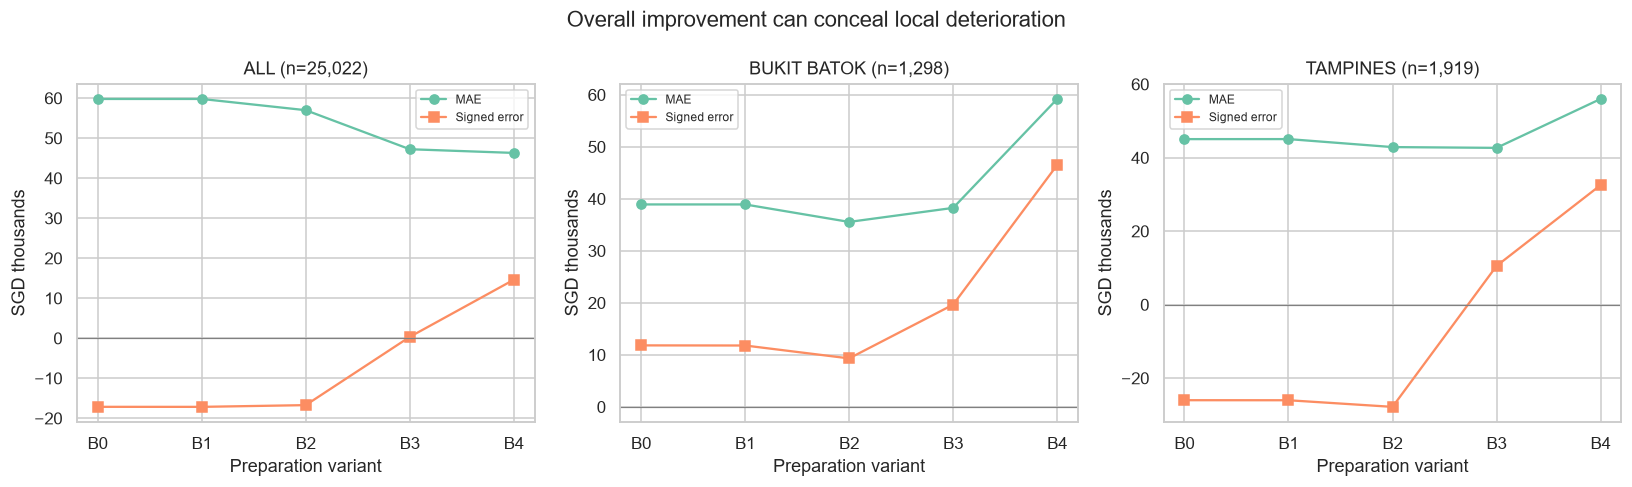

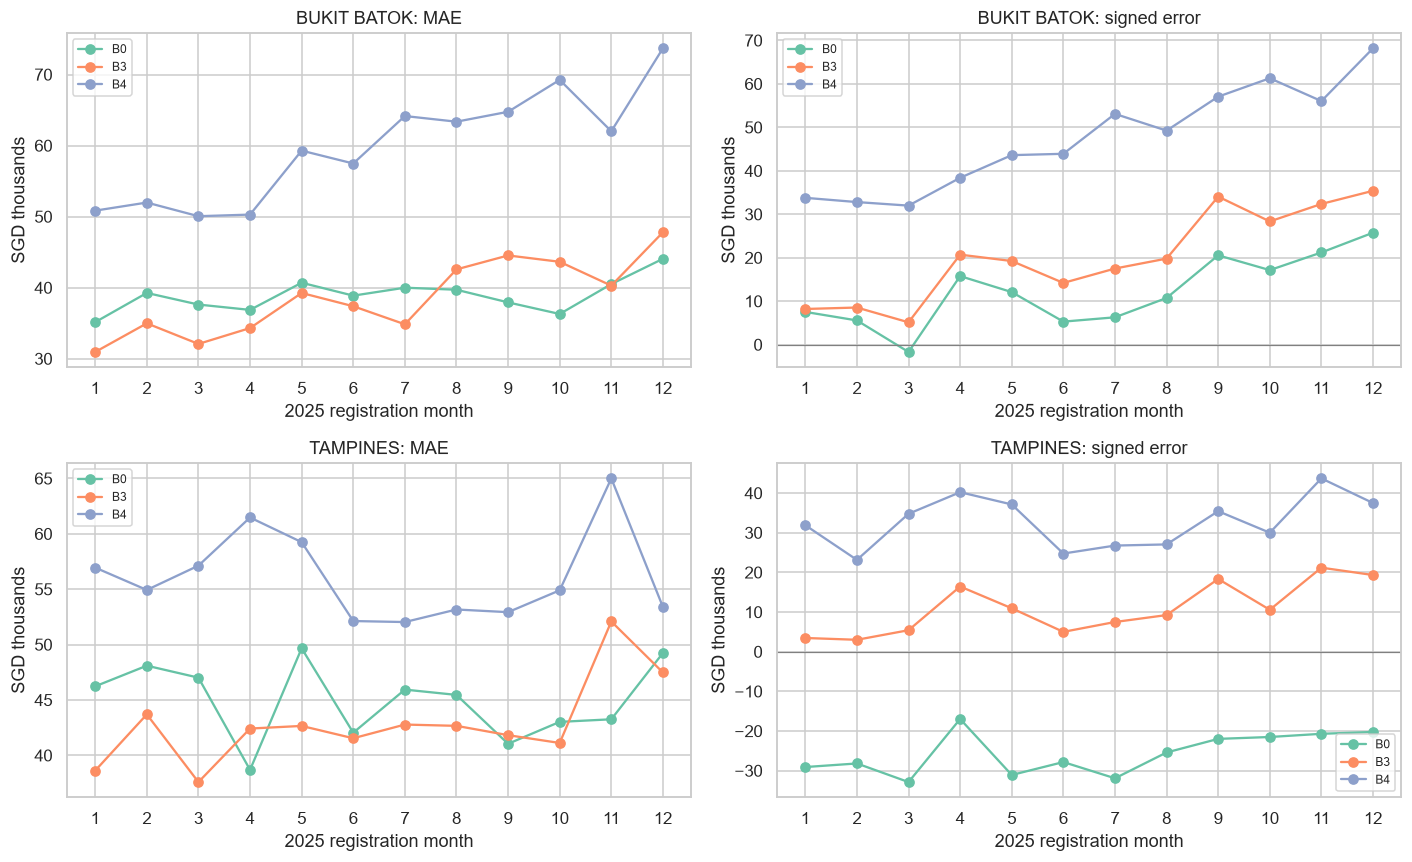

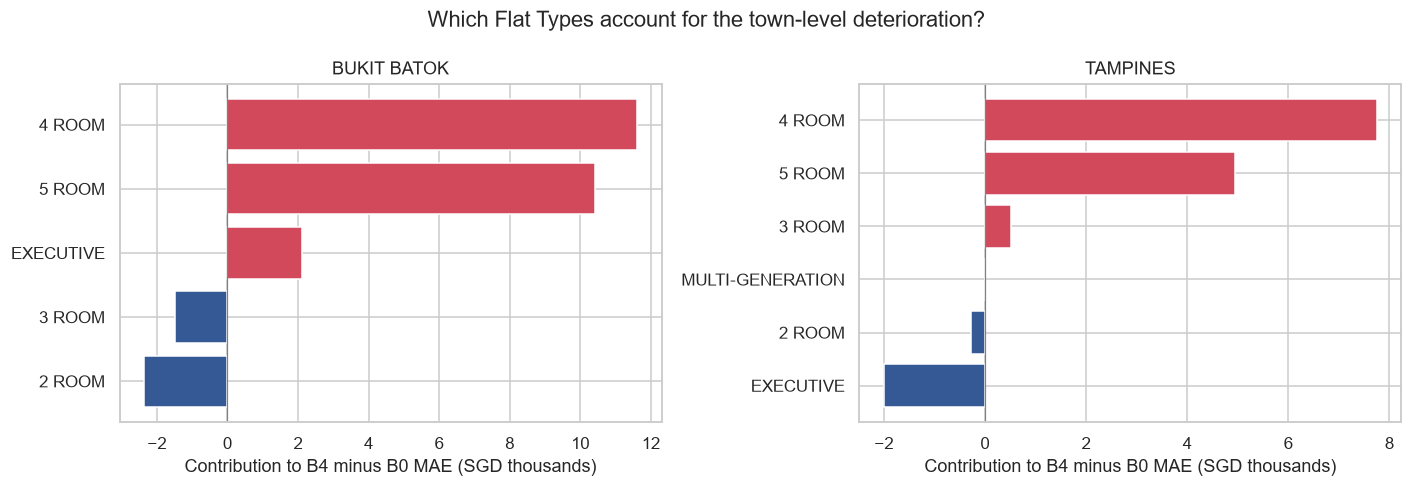

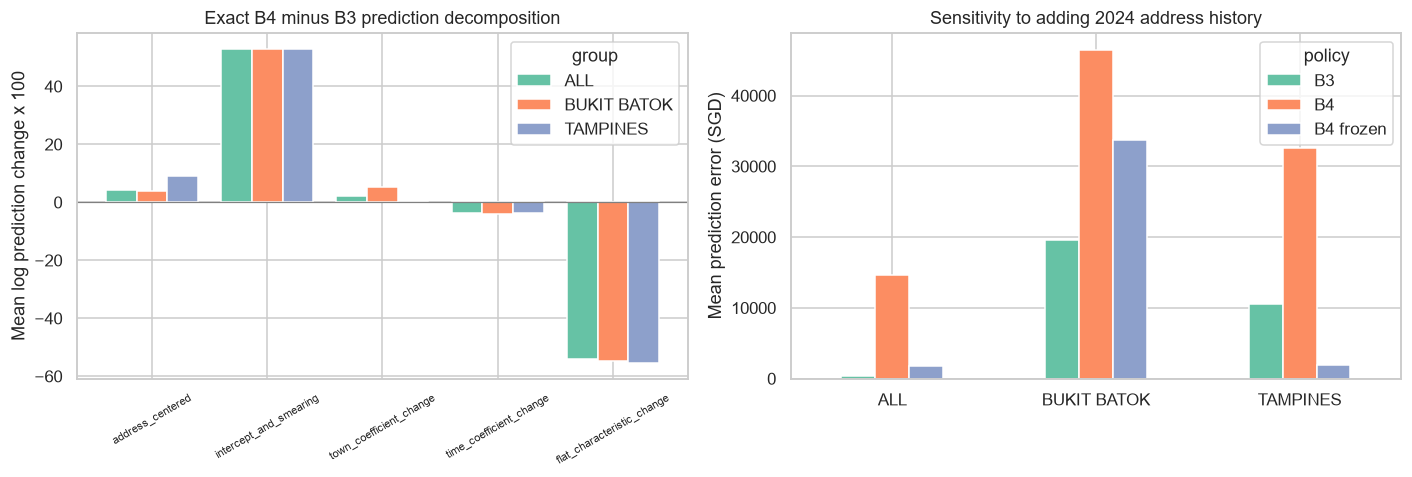

### Interpretation boundaries

The stage table identifies which preparation transition coincides with deterioration. Flat-Type contributions are an exact descriptive allocation of the observed MAE difference; they do not prove that a change in housing mix caused it. Monthly tables distinguish persistent errors from isolated months. Building-cluster bootstrap intervals describe sampling uncertainty within this selected test sample; they are exploratory and do not cover all spatial or market uncertainty.

The decomposition exactly reconstructs the difference in B4 and B3 predictions, including changes to all shared regression coefficients and the smearing correction. It is an algebraic explanation of model behavior, not a causal explanation of housing prices. Centering reallocates the constant between the address and intercept components without changing their sum.

Frozen-history sensitivity holds the trained B4 coefficients fixed and changes only its historical encoding. It tests how strongly recent historical prices move predictions. It is out of the original training-feature distribution and must not be selected as a better production policy using 2025 results. No test-set bias correction or new model selection is performed. A future confirmatory experiment should pre-specify a time-normalized historical encoding and evaluate it on a new chronological holdout.


In [32]:
# Run after Section 14 of the upstream notebook. This code changes no upstream model.
from pathlib import Path
import json

ERROR_OUTPUT = Path('error_analysis_outputs')
ERROR_OUTPUT.mkdir(exist_ok=True)
FOCUS_TOWNS = ['BUKIT BATOK', 'TAMPINES']
VARIANTS = list(pipeline_predictions.columns)
SHORT = {v: v.split(' ')[0] for v in VARIANTS}
V0, V3, V4 = VARIANTS[0], VARIANTS[3], VARIANTS[4]
audit = test.copy()
for variant in VARIANTS:
    audit[f'pred_{SHORT[variant]}'] = pipeline_predictions[variant]
    audit[f'err_{SHORT[variant]}'] = pipeline_predictions[variant] - audit['resale_price']
assert audit.index.is_unique and len(audit) == 25022
assert audit.filter(like='pred_').notna().all().all()

def save_table(name, table):
    table.to_csv(ERROR_OUTPUT / f'{name}.csv', index=False)
    return table

def metric_rows(data, label):
    rows = []
    for variant in VARIANTS:
        error = data[f'err_{SHORT[variant]}']
        rows.append(dict(group=label, variant=SHORT[variant], n=len(data),
            MAE_SGD=error.abs().mean(), RMSE_SGD=np.sqrt((error**2).mean()),
            signed_error_SGD=error.mean(), overprediction_pct=100*error.gt(0).mean(),
            mean_actual_SGD=data['resale_price'].mean()))
    return rows

stage_rows = metric_rows(audit, 'ALL')
for town in FOCUS_TOWNS:
    stage_rows += metric_rows(audit.loc[audit['town'].eq(town)], town)
stage_table = save_table('stage_metrics', pd.DataFrame(stage_rows))
display(stage_table)

# Paired bootstrap: aggregate differences by public building, then sample buildings.
# Keeps all records in each sampled building; does not account for every spatial/time dependency.
rng = np.random.default_rng(20261014)
paired_rows = []
for label, part in [('ALL', audit)] + [(t, audit.loc[audit['town'].eq(t)]) for t in FOCUS_TOWNS]:
    for base in ['B0', 'B3']:
        diff = part['err_B4'].abs() - part[f'err_{base}'].abs()
        clusters = pd.DataFrame({'building':part['building_id'], 'diff':diff}).groupby('building')['diff'].agg(['sum','count'])
        values = clusters.to_numpy()
        samples = []
        for _ in range(1000):
            sampled = values[rng.integers(0,len(values),len(values))]
            samples.append(sampled[:,0].sum()/sampled[:,1].sum())
        low, high = np.quantile(samples,[.025,.975])
        paired_rows.append(dict(group=label, comparison=f'B4 minus {base}', n=len(part),
            buildings=len(clusters), delta_MAE_SGD=diff.mean(), low_95_SGD=low, high_95_SGD=high))
paired_table = save_table('paired_building_bootstrap', pd.DataFrame(paired_rows))
display(paired_table)

monthly_rows = []
for town in FOCUS_TOWNS:
    for month, part in audit.loc[audit['town'].eq(town)].groupby('month'):
        monthly_rows += metric_rows(part, f'{town}|{month}')
monthly_table = pd.DataFrame(monthly_rows)
monthly_table[['town','month']] = monthly_table['group'].str.split('|',expand=True)
save_table('monthly_metrics', monthly_table)

# Within-Flat-Type contributions sum exactly to the town's MAE change.
type_rows = []
for town in FOCUS_TOWNS:
    town_test = audit.loc[audit['town'].eq(town)]
    history = training.loc[training['town'].eq(town)]
    recent = history.loc[history['transaction_year'].eq(2024)]
    for flat_type, part in town_test.groupby('flat_type'):
        h = history.loc[history['flat_type'].eq(flat_type)]
        r = recent.loc[recent['flat_type'].eq(flat_type)]
        delta = part['err_B4'].abs().mean()-part['err_B0'].abs().mean()
        type_rows.append(dict(town=town, flat_type=flat_type, n_2025=len(part),
            share_2025_pct=100*len(part)/len(town_test),
            share_training_pct=100*len(h)/len(history), share_2024_pct=100*len(r)/len(recent),
            MAE_B0=part['err_B0'].abs().mean(), MAE_B3=part['err_B3'].abs().mean(), MAE_B4=part['err_B4'].abs().mean(),
            mean_error_B0=part['err_B0'].mean(), mean_error_B3=part['err_B3'].mean(), mean_error_B4=part['err_B4'].mean(),
            contribution_to_town_delta_SGD=delta*len(part)/len(town_test),
            median_area_2024=r['floor_area_sqm'].median(), median_area_2025=part['floor_area_sqm'].median(),
            median_lease_2024=r['remaining_lease_years'].median(), median_lease_2025=part['remaining_lease_years'].median(),
            median_price_2024=r['resale_price'].median(), median_price_2025=part['resale_price'].median()))
type_table = save_table('flat_type_diagnosis',pd.DataFrame(type_rows))
for town in FOCUS_TOWNS:
    p = audit.loc[audit['town'].eq(town)]
    assert np.isclose(type_table.loc[type_table['town'].eq(town),'contribution_to_town_delta_SGD'].sum(),
                      p['err_B4'].abs().mean()-p['err_B0'].abs().mean())
display(type_table)

# Address history coverage is a support diagnostic, not a claim of causation.
reference = df.loc[df['transaction_year'].lt(2025)]
counts = reference.groupby(address_columns).size().rename('historical_n').reset_index()
support = audit[address_columns].merge(counts,on=address_columns,how='left',sort=False)
audit['historical_n'] = support['historical_n'].fillna(0).to_numpy()
audit['support_band'] = pd.cut(audit['historical_n'],[-1,0,9,29,99,np.inf],
                              labels=['unseen','1-9','10-29','30-99','100+'])
support_rows = []
for label, part in [('ALL',audit)] + [(t,audit.loc[audit['town'].eq(t)]) for t in FOCUS_TOWNS]:
    for band, sub in part.groupby('support_band',observed=True):
        support_rows.append(dict(group=label,support=str(band),n=len(sub),
            MAE_B3=sub['err_B3'].abs().mean(),MAE_B4=sub['err_B4'].abs().mean(),
            signed_error_B4=sub['err_B4'].mean()))
support_table = save_table('historical_address_support',pd.DataFrame(support_rows))
display(support_table)

# Exact decomposition of B4 minus B3 log predictions, centered at training-average encoding.
fit3, fit4 = pipeline_models[V3], pipeline_models[V4]
_, design3 = patsy.dmatrices(pipeline_formulas[V3],training,return_type='dataframe')
_, design4 = patsy.dmatrices(pipeline_formulas[V4],training,return_type='dataframe')
x3 = patsy.build_design_matrices([design3.design_info],test,return_type='dataframe')[0][fit3.params.index]
x4 = patsy.build_design_matrices([design4.design_info],test,return_type='dataframe')[0][fit4.params.index]
common = fit3.params.index
change = x3.mul(fit4.params.reindex(common)-fit3.params,axis=1)
center = training['log_address_te'].mean()
smear3, smear4 = np.exp(fit3.resid).mean(), np.exp(fit4.resid).mean()
components = pd.DataFrame(index=test.index)
components['address_centered'] = fit4.params['log_address_te']*(test['log_address_te']-center)
components['intercept_and_smearing'] = change['Intercept']+fit4.params['log_address_te']*center+np.log(smear4/smear3)
town_terms = [c for c in common if c.startswith(TOWN)]
time_terms = [c for c in common if c.startswith('C(calendar_month)') or 'time_years' in c]
other = [c for c in common if c not in town_terms+time_terms+['Intercept']]
components['town_coefficient_change'] = change[town_terms].sum(axis=1)
components['time_coefficient_change'] = change[time_terms].sum(axis=1)
components['flat_characteristic_change'] = change[other].sum(axis=1)
expected = np.log(audit['pred_B4']/audit['pred_B3'])
max_reconstruction_error = float((components.sum(axis=1)-expected).abs().max())
assert max_reconstruction_error < 1e-9
decomposition_rows = []
for label, idx in [('ALL',audit.index)] + [(t,audit.index[audit['town'].eq(t)]) for t in FOCUS_TOWNS]:
    row = dict(group=label,n=len(idx), **components.loc[idx].mean().mul(100).to_dict())
    row['total_log_prediction_change_x100'] = 100*expected.loc[idx].mean()
    row['mean_prediction_change_SGD'] = (audit.loc[idx,'pred_B4']-audit.loc[idx,'pred_B3']).mean()
    decomposition_rows.append(row)
decomposition_table = save_table('prediction_change_decomposition',pd.DataFrame(decomposition_rows))
display(decomposition_table)

# Fixed-model sensitivity: remove the latest history year, without fitting to 2025 outcomes.
# This diagnoses sensitivity to historical information; it is not a deployable tuned policy.
history_2023 = df.loc[df['transaction_year'].le(2023)]
frozen_encoding = hierarchical_target_encode(history_2023,test[address_columns])
frozen_test = test.copy()
frozen_test['log_address_te'] = np.log(frozen_encoding['address_te'])
frozen_x4 = patsy.build_design_matrices([design4.design_info],frozen_test,return_type='dataframe')[0][fit4.params.index]
frozen_pred = np.exp(fit4.predict(frozen_x4))*smear4
sensitivity_rows = []
for label, part in [('ALL',audit)] + [(t,audit.loc[audit['town'].eq(t)]) for t in FOCUS_TOWNS]:
    for policy,pred in [('B3 no address',part['pred_B3']),('B4 history through 2024',part['pred_B4']),
                        ('B4 fixed model / history through 2023',frozen_pred.loc[part.index])]:
        error = pred-part['resale_price']
        sensitivity_rows.append(dict(group=label,policy=policy,n=len(part),MAE_SGD=error.abs().mean(),
            signed_error_SGD=error.mean(),mean_prediction_SGD=pred.mean()))
sensitivity_table = save_table('frozen_history_sensitivity',pd.DataFrame(sensitivity_rows))
display(sensitivity_table)

encoding_shift = []
for year,part in forecast.groupby('transaction_year'):
    encoding_shift.append(dict(year=int(year),n=len(part),mean_log_address=part['log_address_te'].mean(),
        mean_price=part['resale_price'].mean()))
save_table('encoding_by_year',pd.DataFrame(encoding_shift))

fig,axes=plt.subplots(1,3,figsize=(15,4.5))
for group,ax in zip(['ALL']+FOCUS_TOWNS,axes):
    part=stage_table.loc[stage_table['group'].eq(group)]
    ax.plot(part['variant'],part['MAE_SGD']/1000,marker='o',label='MAE')
    ax.plot(part['variant'],part['signed_error_SGD']/1000,marker='s',label='Signed error')
    ax.axhline(0,color='gray',lw=.8)
    ax.set(title=f'{group} (n={int(part.n.iloc[0]):,})',ylabel='SGD thousands',xlabel='Preparation variant')
    ax.legend(fontsize=8)
fig.suptitle('Overall improvement can conceal local deterioration')
fig.tight_layout()
fig.savefig(ERROR_OUTPUT/'01_stage_error.png',dpi=180,bbox_inches='tight')
plt.show()

fig,axes=plt.subplots(2,2,figsize=(13,8))
for i,town in enumerate(FOCUS_TOWNS):
    p=monthly_table.loc[monthly_table['town'].eq(town)]
    for variant in ['B0','B3','B4']:
        s=p.loc[p['variant'].eq(variant)].sort_values('month')
        months=s['month'].str[-2:].astype(int)
        axes[i,0].plot(months,s['MAE_SGD']/1000,marker='o',label=variant)
        axes[i,1].plot(months,s['signed_error_SGD']/1000,marker='o',label=variant)
    for ax in axes[i]:
        ax.set(xticks=range(1,13),xlabel='2025 registration month',ylabel='SGD thousands')
        ax.legend(fontsize=8)
    axes[i,0].set_title(f'{town}: MAE')
    axes[i,1].set_title(f'{town}: signed error')
    axes[i,1].axhline(0,color='gray',lw=.8)
fig.tight_layout()
fig.savefig(ERROR_OUTPUT/'02_monthly_error.png',dpi=180,bbox_inches='tight')
plt.show()

fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for town,ax in zip(FOCUS_TOWNS,axes):
    p=type_table.loc[type_table['town'].eq(town)].sort_values('contribution_to_town_delta_SGD')
    colors=np.where(p['contribution_to_town_delta_SGD']>0,'#d1495b','#345995')
    ax.barh(p['flat_type'],p['contribution_to_town_delta_SGD']/1000,color=colors)
    ax.axvline(0,color='gray',lw=.8)
    ax.set(title=town,xlabel='Contribution to B4 minus B0 MAE (SGD thousands)')
fig.suptitle('Which Flat Types account for the town-level deterioration?')
fig.tight_layout()
fig.savefig(ERROR_OUTPUT/'03_flat_type_contribution.png',dpi=180,bbox_inches='tight')
plt.show()

fig,axes=plt.subplots(1,2,figsize=(13,4.5))
cols=list(components.columns)
d=decomposition_table.set_index('group')[cols]*1.0
d.T.plot.bar(ax=axes[0],width=.8)
axes[0].axhline(0,color='gray',lw=.8)
axes[0].set(title='Exact B4 minus B3 prediction decomposition',ylabel='Mean log prediction change x 100',xlabel='')
axes[0].tick_params(axis='x',labelrotation=30,labelsize=7)
short_policy={'B3 no address':'B3','B4 history through 2024':'B4','B4 fixed model / history through 2023':'B4 frozen'}
s=sensitivity_table.assign(policy=sensitivity_table['policy'].map(short_policy))
s.pivot(index='group',columns='policy',values='signed_error_SGD').reindex(['ALL']+FOCUS_TOWNS).plot.bar(ax=axes[1])
axes[1].axhline(0,color='gray',lw=.8)
axes[1].set(title='Sensitivity to adding 2024 address history',ylabel='Mean prediction error (SGD)',xlabel='')
axes[1].tick_params(axis='x',labelrotation=0)
fig.tight_layout()
fig.savefig(ERROR_OUTPUT/'04_address_mechanism.png',dpi=180,bbox_inches='tight')
plt.show()

summary = dict(source_rows=len(raw),analysis_rows=len(df),test_rows=len(test),
    source_sha256=metadata['snapshot_sha256'],selected_time_trend=selected_trend,
    address_coefficient=float(fit4.params['log_address_te']),smearing_B3=float(smear3),smearing_B4=float(smear4),
    reconstruction_max_abs_error=max_reconstruction_error,
    monthly_deterioration={t:int((monthly_table.loc[monthly_table.town.eq(t)].pivot(index='month',columns='variant',values='MAE_SGD')['B4'] > monthly_table.loc[monthly_table.town.eq(t)].pivot(index='month',columns='variant',values='MAE_SGD')['B0']).sum()) for t in FOCUS_TOWNS})
(ERROR_OUTPUT/'validation_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
display(Markdown('''### Interpretation boundaries

The stage table identifies which preparation transition coincides with deterioration. Flat-Type contributions are an exact descriptive allocation of the observed MAE difference; they do not prove that a change in housing mix caused it. Monthly tables distinguish persistent errors from isolated months. Building-cluster bootstrap intervals describe sampling uncertainty within this selected test sample; they are exploratory and do not cover all spatial or market uncertainty.

The decomposition exactly reconstructs the difference in B4 and B3 predictions, including changes to all shared regression coefficients and the smearing correction. It is an algebraic explanation of model behavior, not a causal explanation of housing prices. Centering reallocates the constant between the address and intercept components without changing their sum.

Frozen-history sensitivity holds the trained B4 coefficients fixed and changes only its historical encoding. It tests how strongly recent historical prices move predictions. It is out of the original training-feature distribution and must not be selected as a better production policy using 2025 results. No test-set bias correction or new model selection is performed. A future confirmatory experiment should pre-specify a time-normalized historical encoding and evaluate it on a new chronological holdout.
'''))


### 15.1 Composition standardization and support concentration

Holding 2025 within-Flat-Type error differences fixed, replace 2025 Flat-Type shares with 2024 shares. This asks whether the observed deterioration is mainly an arithmetic consequence of different Flat-Type proportions. It does not control every housing attribute or identify a temporal causal effect. Separately allocate B4-minus-B3 MAE changes to historical-address-support bands; positive contributions mean worsening.

In [33]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display
error_tables = Path('error_analysis_outputs')
error_types = pd.read_csv(error_tables / 'flat_type_diagnosis.csv')
error_support = pd.read_csv(error_tables / 'historical_address_support.csv')
mix_rows = []
for town, part in error_types.groupby('town'):
    assert np.isclose(part['share_2024_pct'].sum(), 100)
    delta = part['MAE_B4'] - part['MAE_B0']
    observed = (delta * part['share_2025_pct'] / 100).sum()
    standardized = (delta * part['share_2024_pct'] / 100).sum()
    mix_rows.append({'town': town, 'observed_delta_MAE_SGD': observed,
        'delta_MAE_using_2024_flat_type_shares_SGD': standardized,
        'composition_difference_SGD': observed - standardized})
mix_standardization = pd.DataFrame(mix_rows)
mix_standardization.to_csv(error_tables / 'flat_type_mix_standardization.csv', index=False)
display(mix_standardization)
error_support['share_pct'] = 100 * error_support['n'] / error_support.groupby('group')['n'].transform('sum')
error_support['contribution_to_B4_minus_B3_MAE_SGD'] = (error_support['MAE_B4'] - error_support['MAE_B3']) * error_support['share_pct'] / 100
error_support.to_csv(error_tables / 'support_contribution.csv', index=False)
display(error_support.loc[error_support['group'].isin(['BUKIT BATOK', 'TAMPINES'])])


,town,observed_delta_MAE_SGD,delta_MAE_using_2024_flat_type_shares_SGD,composition_difference_SGD
0,BUKIT BATOK,20279.079,19533.785,745.294
1,TAMPINES,10932.461,10580.699,351.762


,group,support,n,MAE_B3,MAE_B4,signed_error_B4,share_pct,contribution_to_B4_minus_B3_MAE_SGD
5,BUKIT BATOK,unseen,87,70220.048,62728.890,62109.869,6.703,-502.104
6,BUKIT BATOK,1-9,57,31240.623,32123.751,15161.994,4.391,38.781
7,BUKIT BATOK,10-29,831,34851.069,52465.435,38258.263,64.022,11276.994
8,BUKIT BATOK,30-99,323,39638.063,80347.645,69045.115,24.884,10130.351
9,TAMPINES,unseen,53,37392.596,91334.745,91283.613,2.762,1489.804
10,TAMPINES,1-9,355,46514.184,95086.800,83657.934,18.499,8985.554
11,TAMPINES,10-29,1252,42858.839,45094.922,20746.412,65.242,1458.873
12,TAMPINES,30-99,259,37612.403,47820.222,7494.067,13.497,1377.710


### 15.2 Findings and implications

**The deterioration is concentrated at the address step.** BUKIT BATOK MAE is SGD 38,919 (B0), 35,557 (B2), 38,254 (B3), and 59,198 (B4). TAMPINES is SGD 45,055, 42,886, 42,676, and 55,988. Thus cleaning and feature preparation do not generally worsen these towns; B4 adds SGD 20,944 and SGD 13,312 MAE relative to B3. B4 is worse than B0 in all twelve 2025 months in both towns. Building-cluster bootstrap 95% intervals for B4-minus-B3 MAE are approximately SGD 15,143–26,815 and SGD 7,858–18,949, respectively.

**The errors are inside common housing groups, not just rare labels or a changed Flat-Type mix.** 4 ROOM and 5 ROOM contribute SGD 22,026 to BUKIT BATOK's net SGD 20,279 B4-minus-B0 deterioration; other groups offset part of that increase. They contribute SGD 12,704 to TAMPINES's net SGD 10,932 deterioration. Replacing 2025 Flat-Type shares by 2024 shares leaves deterioration of SGD 19,534 and SGD 10,581. The difference attributable to this limited composition standardization is only SGD 745 and SGD 352; unmeasured or within-type changes remain possible.

**Address support matters differently by town.** In TAMPINES, unseen building addresses and addresses with 1–9 historical transactions account for 408/1,919 test records (21.3%) but about 78.7% of the B4-minus-B3 MAE increase. Unseen buildings use the existing parent-level fallback. In BUKIT BATOK, almost all positive deterioration comes from addresses with 10–99 historical transactions, so a small-sample explanation alone is insufficient. Support is associated with error concentration, not an identified cause.

**Address encoding raises predictions and trades off magnitude against calibration.** Overall B3-to-B4 MAE improves by SGD 922, but mean signed error rises from SGD +331 to +14,611. The building-cluster 95% interval for the overall MAE change is SGD -1,960 to +55, so the marginal MAE improvement is not clearly separated from zero under this exploratory uncertainty check. Mean predictions increase by SGD 26,850 in BUKIT BATOK and SGD 22,008 in TAMPINES; their B4 mean signed errors are +46,504 and +32,544.

The address coefficient is positive (0.3825). In a fixed-model sensitivity, using history only through 2023 instead of 2024 reduces mean overprediction to +1,799 overall, +33,767 in BUKIT BATOK, and +1,930 in TAMPINES. This demonstrates sensitivity to the latest historical price information. It is consistent with raw historical prices mixing location, flat composition and market-time information, but does not establish those as unique causes. BUKIT BATOK remains overpredicted even after freezing, so recent-history movement is only part of its issue.

The exact log-prediction decomposition includes the address term, intercept, smearing correction, and all changed shared coefficients; the largest reconstruction error is below 6e-15. The housing and intercept components substantially cancel, so the address coefficient alone cannot explain the full B4-minus-B3 change. The smearing factors are 1.00557 (B3) and 1.00451 (B4); their direction does not explain B4's increased mean overprediction.

**Data-practice implication.** Retain chronological encoding and report MAE, signed errors, support and subgroup results together. Pre-specify a future check of time-normalized or residual-based historical address encoding and use validation data to select it, followed by a new untouched test period. Do not subtract the observed 2025 bias, switch the final policy to frozen history, or tune town-specific weights using these test results. These towns were selected after observing the original test output, so this extension remains exploratory.